# Trabalho 02 — Conhecendo e Pré-processando os Dados
## Mineração de Dados

### Objetivo
Descrever, investigar e preparar a base **4_New-Zealand.csv** para as próximas etapas de mineração, considerando um futuro problema de **regressão para inferir `price`**.

**Base original:** 25.006 registros × 16 atributos  
**Variável alvo:** `price`

### Estratégia
**Entender → detectar problemas → investigar → tratar → validar → preparar para regressão**

> Os códigos permanecem no notebook como memória de cálculo e apoio técnico; a apresentação será conduzida principalmente pelas células Markdown.

# 1. Inventário inicial: o que esperamos usar?

Antes da AED, os atributos foram classificados por significado e possível utilidade para a regressão.

- **Alvo:** `price`
- **Candidatos:** localização, `room_type`, noites mínimas, avaliações, quantidade de anúncios do host e disponibilidade
- **Prováveis exclusões:** `id`, `name`, `host_id`, `host_name`
- **A avaliar:** `last_review`

O inventário foi tratado como **hipótese inicial**, a ser confirmada ou rejeitada pelos dados.

> O dicionário previa 17 atributos, mas a base do grupo possui 16: `license` não está presente.

In [3]:
# ============================================================
# Carregamento da base de dados / inspeção da estrutura
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Simples ajuste no tamalho da exibição no VS Code
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

arquivo = "4_New-Zealand.csv"
dados = pd.read_csv(arquivo, skipinitialspace=True)

print(f"Base {arquivo} carregada com sucesso!")
print(f"Dimensão da base: {dados.shape[0]} linhas x {dados.shape[1]} colunas\n")

#print(f"Quantidade de atributos: {sum(dados.columns.value_counts())}")
# Lista numerada dos atributos
#for i, coluna in enumerate(dados.columns, start=0):
#    print(f"{i:2d} - {coluna}")

print("Dados.info():")
dados.info()

# Dados faltantes: Hostname, price, [COMO AUTOMATIZAR ESSA COMPARAÇÃO]

Base 4_New-Zealand.csv carregada com sucesso!
Dimensão da base: 25006 linhas x 16 colunas

Dados.info():
<class 'pandas.DataFrame'>
RangeIndex: 25006 entries, 0 to 25005
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              25006 non-null  float64
 1   name                            25006 non-null  str    
 2   host_id                         25005 non-null  str    
 3   host_name                       24991 non-null  str    
 4   neighbourhood_group             25006 non-null  str    
 5   neighbourhood                   25006 non-null  str    
 6   latitude                        25006 non-null  str    
 7   longitude                       25006 non-null  float64
 8   room_type                       25006 non-null  str    
 9   price                           22666 non-null  str    
 10  minimum_nights                  25005 non-null  float64
 11 

# 2. A “pegadinha” da base: campos deslocados

A primeira inspeção mostrou tipos incompatíveis com o significado dos atributos:

- `price`, `latitude` e `reviews_per_month` foram carregados como texto;
- datas apareciam em posições inesperadas;
- categorias como `Entire home/apt` apareciam onde deveria existir preço.

A investigação revelou **17 registros com deslocamento entre colunas**.

### Por que tratar isso primeiro?
Sem essa correção, valores deslocados poderiam ser interpretados posteriormente como:
- outliers;
- valores ausentes;
- ou valores extremos legítimos.

### Decisão
Como os 17 registros representavam cerca de **0,07% da base** e alguns não podiam ser reconstruídos com segurança, eles foram removidos.

> Só depois corrigimos os tipos e seguimos para a AED.

In [4]:
# ============================================================
# RESULTADO ANÁLISE: Colunas com tipos inconsistentes
# ============================================================

# 1 - price → str, mas deveria ser numérico;
# 2 - latitude → str, mas deveria ser numérico;
# 3 - reviews_per_month → str, mas deveria ser numérico;
# 4 - host_id → str, mas conceitualmente é identificador, então isso não é problema;
# 5 - last_review → str, mas deveria ser data.

# print("Price:")
# print(dados["price"].unique()[:20])

# print("\nLatitude:")
# print(dados["latitude"].unique()[:20])

# print("\nReviews_per_month")
# print(dados["reviews_per_month"].unique()[:20])

# print("\nLast Review")
# print(dados["last_review"].unique()[:20])


# Identificação de valores não numéricos

colunas_numericas = [
    "latitude",
    "longitude",
    "price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365"
]

linhas_inconsistentes = pd.Series(False, index=dados.index)

for coluna in colunas_numericas:

    convertido = pd.to_numeric(dados[coluna], errors="coerce")

    inconsistente = (
        dados[coluna].notna() &
        convertido.isna()
    )

    print(f"{coluna}: {inconsistente.sum()} valores inconsistentes")

    linhas_inconsistentes |= inconsistente

print(
    f"\nTotal de registros com pelo menos uma inconsistência: "
    f"{linhas_inconsistentes.sum()}"
)

quantidade_inconsistentes = linhas_inconsistentes.sum()
percentual_inconsistentes = (quantidade_inconsistentes / len(dados)) * 100
print(f"\nTotal de registros inconsistentes: {quantidade_inconsistentes}")
print(f"Percentual da base: {percentual_inconsistentes:.2f}%")


latitude: 17 valores inconsistentes
longitude: 0 valores inconsistentes
price: 17 valores inconsistentes
minimum_nights: 0 valores inconsistentes
number_of_reviews: 0 valores inconsistentes
reviews_per_month: 16 valores inconsistentes
calculated_host_listings_count: 0 valores inconsistentes
availability_365: 0 valores inconsistentes

Total de registros com pelo menos uma inconsistência: 17

Total de registros inconsistentes: 17
Percentual da base: 0.07%


In [5]:
# Visualização das linhas inconsistentes

price_numerico = pd.to_numeric(dados["price"], errors="coerce")
problemas_price = dados[dados["price"].notna() & price_numerico.isna()]
display(problemas_price)

#display(dados.loc[[381]])

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
381,1.161999e+18,Modern and Central - Christchurch Apartment&nbsp,NaN,145244100,Bachcare,Christchurch City,Central Ward,-43.525690,172.63976,Entire home/apt,308.0,1,0,NaN,NaN,1760
2499,4.086841e+07,Enjoy comfort and peace,whole house.,94159699,Jan,Gisborne District,Gisborne Ward,-38.667490,178.04262,Entire home/apt,375.0,2,3,2020-01-11,0.05,1
2527,1.002429e+18,Country class,5- 6 persons - beach close by,61649087,Kalev,Gisborne District,Gisborne Ward,-38.663260,178.07991,Entire home/apt,350.0,2,27,2025-01-04,2.07,1
6809,7.973914e+17,Boutique cottage,short walk to waterfalls & town,26270372,Lisa,Far North District,Bay of Islands-Whangaroa Ward,-35.232582,173.9619088,Entire home/apt,177.0,2,98,2025-01-04,4.10,1
7176,1.288687e+18,Family-friendly,Stylish & Sleek,68131173,Junlan,Christchurch City,Riccarton Ward,-43.527113,172.558416953304,Entire home/apt,158.0,2,1,2024-12-29,1.00,1
8768,3.327408e+07,Luxury Home with Pool/Spa,close to beach/ 4 bed,235073030,Jodi,Thames-Coromandel District,South Eastern Ward,-37.214710,175.87337,Entire home/apt,621.0,2,45,2024-08-24,0.74,1
11546,3.903395e+07,Quiet room in a rural setting,close to The Lakes,125279195,Sally,Western Bay of Plenty District,Kaimai Ward,-37.774950,176.10569,Private room,NaN,2,17,2024-04-27,0.67,1
12391,8.510109e+17,Azores Harbourside Studio,self contained unit,155316152,Shane,Tauranga City,Te Papa-Welcome Bay Ward,-37.725239,176.191715284656,Entire home/apt,136.0,1,35,2025-01-04,1.61,2
14832,2.331126e+07,Homely and spacious,a Home away from Home,173581233,Laurian,Wellington City,Motukairangi/Eastern Ward,-41.318770,174.79239,Private room,80.0,2,33,2024-11-08,0.40,2
16064,5.265532e+07,Valley Views - rural studio unit,+ stunning views,340853882,Lara,Nelson City,Area Outside Ward,-41.215190,173.40007,Entire home/apt,121.0,1,178,2024-12-28,4.77,1


In [6]:
# ============================================================
# TRATAMENTO - Remoção dos registros inconsistentes
# ============================================================

# Remove os registros que apresentam inconsistencias
dados = dados[~linhas_inconsistentes].copy()

# Reorganiza os indices apos a remoção
dados.reset_index(drop=True, inplace=True)

print(f"Dimensão da base após o tratamento: {dados.shape[0]} linhas x {dados.shape[1]} colunas")

Dimensão da base após o tratamento: 24989 linhas x 16 colunas


In [7]:
# ============================================================
# Conversão dos tipos
# ============================================================

dados["price"] = pd.to_numeric(dados["price"])
dados["latitude"] = pd.to_numeric(dados["latitude"])
dados["reviews_per_month"] = pd.to_numeric(dados["reviews_per_month"])
dados["last_review"] = pd.to_datetime(dados["last_review"])

dados.info()

<class 'pandas.DataFrame'>
RangeIndex: 24989 entries, 0 to 24988
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   id                              24989 non-null  float64       
 1   name                            24989 non-null  str           
 2   host_id                         24989 non-null  str           
 3   host_name                       24974 non-null  str           
 4   neighbourhood_group             24989 non-null  str           
 5   neighbourhood                   24989 non-null  str           
 6   latitude                        24989 non-null  float64       
 7   longitude                       24989 non-null  float64       
 8   room_type                       24989 non-null  str           
 9   price                           22649 non-null  float64       
 10  minimum_nights                  24989 non-null  float64       
 11  number_of_rev

In [8]:
# ============================================================
# Inspeção do conteúdo
# (linhas, colunas, conteúdo, formato, etc...)
# ============================================================

# Exibe as cinco primeiras linhas da base
print("Primeiros registros:")
#print(dados.head()) 
display(dados.head())

# Exibe as cinco últimas linhas da base
print("Últimos registros")
display(dados.tail())


Primeiros registros:


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,1.196781e+18,Premium Private 8-bed Suite in City Centre,573074023,Drifter,Christchurch City,Central Ward,-43.533280,172.639990,Private room,521.0,1.0,0,NaT,NaN,11.0,8
1,9.677601e+17,Walk to Riverside Market: 4 bed 4 bath w/ Car ...,482671075,Carebnb,Christchurch City,Central Ward,-43.535568,172.631885,Entire home/apt,474.0,1.0,129,2025-01-01,8.08,120.0,201
2,4.035544e+07,Fabulous townhouse in Christchurch centre,86216394,Min,Christchurch City,Central Ward,-43.527530,172.643050,Entire home/apt,106.0,1.0,337,2024-12-01,5.44,47.0,39
3,1.299499e+18,Bright and Inviting Studio Near South City Mall,551181197,Paula Kat Charlotte,Christchurch City,Central Ward,-43.539097,172.635406,Entire home/apt,144.0,1.0,2,2024-12-15,1.76,113.0,246
4,1.300265e+18,Ultimate Convenience 2BR Close to Shopping Centre,482671075,Carebnb,Christchurch City,Central Ward,-43.537029,172.638530,Entire home/apt,224.0,1.0,1,2024-12-30,1.00,120.0,84


Últimos registros


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
24984,3.736784e+07,Beach Studio Retreat!,281578379,Karen,Auckland,Albany Ward,-36.712150,174.750630,Entire home/apt,126.0,2.0,55,2024-12-21,0.84,1.0,211
24985,1.290287e+18,Kuaotunu beach cabin,271733308,Marion,Thames-Coromandel District,Mercury Bay Ward,-36.726177,175.699487,Entire home/apt,160.0,2.0,9,2025-01-04,6.75,1.0,221
24986,4.799761e+07,Sunset Everyday,2559050,Shariff,Kapiti Coast District,Paekākāriki-Raumati Ward,-40.927980,174.975620,Entire home/apt,600.0,7.0,6,2023-03-15,0.16,1.0,364
24987,8.410228e+17,Paradise Heights,504098753,Alwin,Auckland,Howick Ward,-36.925890,174.885350,Private room,58.0,1.0,12,2024-08-23,0.55,1.0,155
24988,9.172107e+06,Whangamata Beach at your back door,47222885,Steve,Thames-Coromandel District,South Eastern Ward,-37.212490,175.878650,Entire home/apt,500.0,1.0,6,2024-02-24,0.06,2.0,340


In [9]:
# ============================================================
# Inspeção das estatísticas descritivas para cada atributo numérico
# ============================================================
display(dados.describe())

#Todos os dados de longitude preechidos 


,id,latitude,longitude,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
count,2.498900e+04,24989.000000,24989.000000,22649.000000,24989.000000,24989.000000,22211,22211.000000,24989.000000,24989.000000
mean,5.981961e+17,-40.026148,173.617857,416.070511,2.447597,57.173756,2024-09-01 05:04:38.942866,1.784724,69.898075,185.075993
min,4.607100e+04,-46.906730,-176.561210,14.000000,1.000000,0.000000,2013-04-04 00:00:00,0.010000,1.000000,0.000000
25%,3.883016e+07,-43.520586,172.635120,140.000000,1.000000,3.000000,2024-09-30 00:00:00,0.470000,1.000000,66.000000
50%,7.575025e+17,-39.054540,174.739403,229.000000,2.000000,18.000000,2024-12-16 00:00:00,1.130000,2.000000,178.000000
75%,1.086714e+18,-36.917360,175.426140,390.000000,2.000000,65.000000,2024-12-30 00:00:00,2.440000,6.000000,312.000000
max,1.326303e+18,-34.515710,178.430720,44825.000000,1000.000000,1402.000000,2025-01-05 00:00:00,16.870000,1760.000000,365.000000
std,5.251606e+17,3.288945,5.985232,2015.562971,13.835400,101.346071,NaN,1.877224,314.868291,127.433347


# 3. Valores ausentes: cada ausência tem um significado

### Avaliações
`last_review` e `reviews_per_month` tinham **2.778 ausentes**.

Todos esses casos apresentavam:
> `number_of_reviews = 0`

**Tratamento:**
- `reviews_per_month` → preenchido com **0**
- `last_review` → mantido ausente, pois não existe data de última avaliação

### Variável alvo
Foram encontrados **2.340 registros sem `price` (9,36%)**.

Antes de removê-los, investigamos se a ausência apresentava algum padrão.

In [10]:
# ============================================================
# Análise de valores ausentes
# ============================================================

### >>>>> Antes ou depois gerar um CSV com a base alterada para conferir visualmente no excel valores extremos para os atributos.

# Calcula a quantidade de valores ausentes por atributo
qtde_linhas = len(dados)
qtde_presentes = dados.count()
qtde_ausentes = dados.isna().sum()

# Calculo percentual dos valores ausentes
perc_ausentes = (qtde_ausentes / len(dados)) * 100

# Cria uma tabela para facilitar a análise
ausentes = pd.DataFrame({"Qtde Linhas":qtde_linhas, "Qtde registros":qtde_presentes,"Qtde Ausentes": qtde_ausentes, "Percentual":perc_ausentes})
display(ausentes)
#display(ausentes[ausentes["Qtde Ausentes"] > 0]) #CUIDADO! Podem haver atribuitos categóricos que não aparecem no describe (somente estatísticas numéricas)

# IPC: NaN sem sempre é um problema: Se o imovel nunca recebeu avaliação, não haverá data ou média de avaliações, por exemplo

,Qtde Linhas,Qtde registros,Qtde Ausentes,Percentual
id,24989,24989,0,0.000000
name,24989,24989,0,0.000000
host_id,24989,24989,0,0.000000
host_name,24989,24974,15,0.060026
neighbourhood_group,24989,24989,0,0.000000
neighbourhood,24989,24989,0,0.000000
latitude,24989,24989,0,0.000000
longitude,24989,24989,0,0.000000
room_type,24989,24989,0,0.000000
price,24989,22649,2340,9.364120


In [11]:
# ============================================================
# ANÁLISE - Valores ausentes relacionados às avaliações
# ============================================================

# Seleciona registros sem informação da última avaliação
sem_avaliacao = dados[dados["last_review"].isna()]
sem_review_per_mont = dados["reviews_per_month"].isna().sum()

print(f"Registros sem last_review: {len(sem_avaliacao)}")
print(f"Registros sem review_per_month: {sem_review_per_mont}")

# Verifica quantos desses registros possuem zero avaliações
print("Registros sem last_review e com number_of_viwers = 0:", (sem_avaliacao["number_of_reviews"] == 0).sum())

Registros sem last_review: 2778
Registros sem review_per_month: 2778
Registros sem last_review e com number_of_viwers = 0: 2778


In [12]:
# ============================================================
# EXPORTAÇÃO - Base para validação visual
# ============================================================

arquivo_validacao = "4_New-Zealand-validacao.xlsx"
dados.to_excel(arquivo_validacao, index=False)
print(f"Arquivo {arquivo_validacao} gerado com sucesso")

Arquivo 4_New-Zealand-validacao.xlsx gerado com sucesso


In [13]:
# ============================================================
# TRATAMENTO - Valores ausentes em reviews_per_month
# ============================================================

# Anúncios sem avaliações recebem 0 avaliações por mês
dados["reviews_per_month"] = dados["reviews_per_month"].fillna(0) #fillna() substitui valores nulos / dropna() deleta valores nulos

# Verifica o resultado do tratamento
print(
    "Valores ausentes em reviews_per_month:",
    dados["reviews_per_month"].isna().sum()
)

Valores ausentes em reviews_per_month: 0


In [14]:
# ============================================================
# ANÁLISE - Valores ausentes em price
# ============================================================

# Seleciona os registros sem informação de preço
sem_price = dados[dados["price"].isna()]

print(f"Registros sem price: {len(sem_price)}") #Len mostra somente a quantidade
print(f"Percentual da base: {(len(sem_price) / len(dados)) *100:.2f}%")

# Distribuição dos registros sem preço por tipo de imóvel
print("\nRegistros sem price por room_type:")
print(sem_price["room_type"].value_counts())

# Distribuição dos registros sem preço por região
print("\nRegistros sem price por neighbourhood_group")
print(sem_price["neighbourhood_group"].value_counts())

dados.head(10)


Registros sem price: 2340
Percentual da base: 9.36%

Registros sem price por room_type:
room_type
Entire home/apt    1750
Private room        569
Hotel room           18
Shared room           3
Name: count, dtype: int64

Registros sem price por neighbourhood_group
neighbourhood_group
Auckland                        464
Queenstown-Lakes District       341
Tauranga City                   154
Christchurch City               128
Taupo District                  109
                               ... 
Gore District                     2
Waimate District                  1
Stratford District                1
Ōtorohanga District               1
Central Hawke's Bay District      1
Name: count, Length: 63, dtype: int64


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,1.196781e+18,Premium Private 8-bed Suite in City Centre,573074023,Drifter,Christchurch City,Central Ward,-43.533280,172.639990,Private room,521.0,1.0,0,NaT,0.00,11.0,8
1,9.677601e+17,Walk to Riverside Market: 4 bed 4 bath w/ Car ...,482671075,Carebnb,Christchurch City,Central Ward,-43.535568,172.631885,Entire home/apt,474.0,1.0,129,2025-01-01,8.08,120.0,201
2,4.035544e+07,Fabulous townhouse in Christchurch centre,86216394,Min,Christchurch City,Central Ward,-43.527530,172.643050,Entire home/apt,106.0,1.0,337,2024-12-01,5.44,47.0,39
3,1.299499e+18,Bright and Inviting Studio Near South City Mall,551181197,Paula Kat Charlotte,Christchurch City,Central Ward,-43.539097,172.635406,Entire home/apt,144.0,1.0,2,2024-12-15,1.76,113.0,246
4,1.300265e+18,Ultimate Convenience 2BR Close to Shopping Centre,482671075,Carebnb,Christchurch City,Central Ward,-43.537029,172.638530,Entire home/apt,224.0,1.0,1,2024-12-30,1.00,120.0,84
5,2.966176e+07,Luxury/BrandyNew 2 bedroom heart CDB Free Carpk!,56790664,Candy,Christchurch City,Central Ward,-43.536179,172.635303,Entire home/apt,165.0,1.0,74,2025-01-03,6.03,5.0,142
6,1.030689e+18,Quaint Worcester Quarters: 3BR Delight,202585247,Ohana,Christchurch City,Central Ward,-43.531400,172.644500,Entire home/apt,131.0,1.0,47,2024-12-17,3.47,145.0,42
7,3.887825e+07,Modern Central City 4 Bedroom Townhouse,239600018,Nathalie Eugenie,Christchurch City,Central Ward,-43.525090,172.642060,Entire home/apt,396.0,2.0,84,2024-12-22,1.37,1.0,235
8,1.102514e+18,Central Oasis: Charming Studio with Backyard,551181197,Paula Kat Charlotte,Christchurch City,Central Ward,-43.538490,172.631400,Entire home/apt,129.0,1.0,19,2024-12-30,1.83,113.0,242
9,1.168535e+18,Haka House - Twin Room Ensuite,565751605,Aashish,Christchurch City,Central Ward,-43.532205,172.629823,Private room,174.0,1.0,0,NaT,0.00,10.0,207


In [15]:
# ============================================================
# ANÁLISE - Possíveis relações com a ausência de price
# ============================================================

# Cria uma variável temporária:
# 0 - possui price
# 1 - price ausente
dados["price_ausente"] = dados["price"].isna().astype(int) # isna() identifica os valores ausentes (True/False) e astype(int) converte para 1 (price ausente)/0 (possui price)
print(dados["price_ausente"].value_counts())

# Ausência de price x atributos numéricos
atributos_numericos = [
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365"
]

# Compara a média dos atributos entre anúncios
# com price (0) e sem price (1)
comparacao_price = dados.groupby("price_ausente")[atributos_numericos].mean()
display(comparacao_price)

# Compara a mediana dos atributos entre os anúncios
comparacao_mediana = dados.groupby("price_ausente")[atributos_numericos].median()
display(comparacao_mediana)




price_ausente
0    22649
1     2340
Name: count, dtype: int64


,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
price_ausente,,,,,
0,2.186278,58.744889,1.635591,74.240408,197.825908
1,4.976923,41.966667,1.109406,27.868376,61.668803


,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
price_ausente,,,,,
0,2.0,19.0,1.000,2.0,205.0
1,2.0,11.0,0.585,1.0,0.0


In [ ]:
# | Atributo                         | Com `price` | Sem `price` | Leitura inicial                    |
# | -------------------------------- | ----------: | ----------: | ---------------------------------- |
# | `minimum_nights`                 |           2 |           2 | Muito semelhante                   |
# | `number_of_reviews`              |          19 |          11 | Sem preço têm menos avaliações     |
# | `reviews_per_month`              |        1,00 |       0,585 | Sem preço têm menos avaliações/mês |
# | `calculated_host_listings_count` |           2 |           1 | Alguma diferença                   |
# | `availability_365`               |     **205** |       **0** | **Diferença muito expressiva**     |

# A ausência de price não parece simplesmente sem padrão.
# availability_365 merece ser investigado
# A mediana 0 entre os anúncios sem preço é um sinal forte.
# Uma hipótese plausível — ainda apenas hipótese — seria:
# anúncios indisponíveis ou pouco disponíveis podem apresentar maior frequência de price ausente.

# ============================================================
# ANÁLISE - Price ausente x availability_365
# ============================================================

# Quantidade de registros com disponibilidade igual a zero
comparacao_disponibilidade = pd.crosstab(dados["price_ausente"], dados["availability_365"] == 0)
comparacao_disponibilidade = comparacao_disponibilidade.rename(index={0: "Com Price", 1: "Sem Price"})
display(comparacao_disponibilidade)

comparacao_disponibilidade_perc = pd.crosstab(dados["price_ausente"], dados["availability_365"] == 0, normalize="index") * 100
comparacao_disponibilidade_perc = comparacao_disponibilidade_perc.rename(index={0: "Com Price", 1: "Sem Price"})
display(comparacao_disponibilidade_perc)

print("Entre os anúncios com preço, apenas 2,19% têm disponibilidade zero. Entre os anúncios sem preço, 60,85% têm disponibilidade zero.")


availability_365,False,True
price_ausente,,
Com Price,22152,497
Sem Price,916,1424


availability_365,False,True
price_ausente,,
Com Price,97.805643,2.194357
Sem Price,39.145299,60.854701


Entre os anúncios com preço, apenas 2,19% têm disponibilidade zero. Entre os anúncios sem preço, 60,85% têm disponibilidade zero.


# 4. `price` ausente estava associado à indisponibilidade

Entre anúncios **com `price`**, apenas **2,19%** tinham `availability_365 = 0`.

Entre anúncios **sem `price`**, **60,85%** tinham disponibilidade zero.

### Teste estatístico
- Qui-quadrado = **10.275,82**
- `p < 0,05`
- Phi = **0,6413**

Há uma associação expressiva, mas **não causal**: 39,15% dos anúncios sem preço ainda tinham disponibilidade > 0.

### Tratamento
Como `price` é a variável alvo, não faria sentido imputá-lo artificialmente.

> Os **2.340 registros sem `price` foram removidos**.

In [17]:
# ============================================================
# ANÁLISE - Associação entre ausência de price e disponibilidade - Teste Qui-quadrado
# ============================================================

import scipy.stats as ss

# Cria a tabela de contingência
tabela_contingencia = pd.crosstab(dados["price_ausente"], dados["availability_365"] == 0)

# Teste Qui-quadrado de independência
qui2, p_valor, graus_liberdade, frequencias_esperadas = ss.chi2_contingency(tabela_contingencia)
print(f"Qui-quadrado: {qui2:.4f}")
print(f"p-valor: {p_valor:.4e}")

print ("\nSe p-valor < 0,05. \nRejeitamos a hipótese nula de independência. \nPortanto: Há evidência estatística de associação entre a ausência de price e availability_365 = 0.")

# O que ainda falta?

# O Qui-quadrado mostrou que existe associação, mas não sua intensidade. E, com quase 25 mil registros, mesmo associações pequenas podem resultar em p-valores muito baixos.

# Por isso, agora faz sentido medir a força da associação.

Qui-quadrado: 10275.8206
p-valor: 0.0000e+00

Se p-valor < 0,05. 
Rejeitamos a hipótese nula de independência. 
Portanto: Há evidência estatística de associação entre a ausência de price e availability_365 = 0.


In [18]:
# ============================================================
# ANÁLISE - Força da associação - Coeficiente Phi
# ============================================================

qtde_observacoes = tabela_contingencia.to_numpy().sum()
phi_intensidade_associacao = np.sqrt(qui2 / qtde_observacoes)
print(f"Coeficiente Phi: {phi_intensidade_associacao:.4f}")

print("Confirma que não temos apenas significância estatística; temos uma associação relevante entre ausência de price e indisponibilidade (availability_365 = 0).\n >>> A magnitude do coeficiente indica associação expressiva <<<")

Coeficiente Phi: 0.6413
Confirma que não temos apenas significância estatística; temos uma associação relevante entre ausência de price e indisponibilidade (availability_365 = 0).
 >>> A magnitude do coeficiente indica associação expressiva <<<


In [19]:
# Como price é o alvo da futura regressão, os 2.340 registros sem preço não poderão participar do treinamento supervisionado. 
# Portanto, agora podemos removê-los.

# ============================================================
# TRATAMENTO - Valores ausentes em price
# ============================================================

# Remove os registros que não possuem a variável alvo price
dados = dados.dropna(subset=["price"]).copy()

# Reorganiza os índices após a remoção
dados.reset_index(drop=True, inplace=True)

print(f"Quantidade de registros após tratamento: {len(dados)}")
print(f"Valores ausentes em price: {dados["price"].isna().sum()}")

# Remove a variável auxiliar utilizada somente na análise
dados.drop(columns=["price_ausente"], inplace=True)

Quantidade de registros após tratamento: 22649
Valores ausentes em price: 0


# 5. Consistência geral da base

Após os tratamentos iniciais foram verificadas:

### Duplicidades
- **0 registros totalmente duplicados**
- **0 IDs duplicados**

### Domínio
Nenhum valor inválido foi encontrado para:
- preços e noites mínimas;
- avaliações;
- disponibilidade entre 0 e 365;
- latitude e longitude em seus limites possíveis.

> A base estava estruturalmente consistente antes de iniciar a análise de outliers.

In [20]:
# ============================================================
# Análise de registros duplicados
# ============================================================

# Distinção importante. Podemos ter:
# Duplicidade exata: todas as 16 colunas são iguais.
# Duplicidade de id: o mesmo anúncio aparece mais de uma vez, talvez com alguma informação diferente.

# Registros totalmente duplicados
duplicados = dados.duplicated().sum()
print(f"Registros totalmente duplicados: {duplicados}")

# Duplicidade de id_registro
ids_duplicados = dados["id"].duplicated().sum()
print(f"Registros com ID duplicado: {ids_duplicados}")

Registros totalmente duplicados: 0
Registros com ID duplicado: 0


In [21]:
# ============================================================
# Análise de inconsistências de domínio
# ============================================================

# Verifica valores incompatíveis com o significado dos atributos

print("Price <= 0: ", (dados["price"] <= 0).sum())
print("Minimun_nights <= 0: ", (dados["minimum_nights"] <= 0).sum())
print("Number of reviews < 0: ", (dados["number_of_reviews"] < 0).sum())
print("Reviews per month < 0: ", (dados["reviews_per_month"] < 0).sum())
print("Calculated_host_listings_count < 0: ", (dados["calculated_host_listings_count"] < 0).sum())
print("Avaialibity_365 fora do intervalo 0 a 365: ", ((dados["availability_365"] < 0) | (dados["availability_365"] > 365)).sum())
print("Latitude fora do intervalo -90 a 90: ", ((dados["latitude"] < -90) | (dados["latitude"] > 90)).sum())
print("Longitude fora do intervalo -180 a 180: ", ((dados["longitude"] < -180) | (dados["longitude"] > 180)).sum())



Price <= 0:  0
Minimun_nights <= 0:  0
Number of reviews < 0:  0
Reviews per month < 0:  0
Calculated_host_listings_count < 0:  0
Avaialibity_365 fora do intervalo 0 a 365:  0
Latitude fora do intervalo -90 a 90:  0
Longitude fora do intervalo -180 a 180:  0


# 6. Outliers: detectar não significa remover

O **IQR** foi usado como ferramenta de detecção.

A regra adotada foi:

> **detectar → quantificar → investigar → decidir**

Nenhum registro foi excluído somente por ultrapassar o limite do IQR.

### Exemplo: `price`
- Q1 = **140**
- Q3 = **390**
- limite superior IQR = **765**
- **1.462 registros (6,46%)** acima do limite

Um preço > 765 pode ser perfeitamente legítimo. Por isso, investigamos a cauda da distribuição em vez de remover automaticamente.

count    22649.000000
mean       416.070511
std       2015.562971
min         14.000000
25%        140.000000
50%        229.000000
75%        390.000000
max      44825.000000
Name: price, dtype: float64


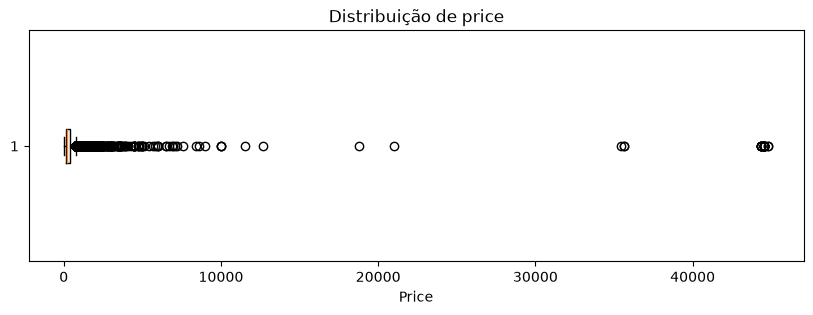

In [22]:
# ============================================================
# Análise de outliers - price
# ============================================================

# Estatísticas descritivas para price
print(dados["price"].describe())

# Boxplot para análise visual
plt.figure(figsize=(10,3))
plt.boxplot(dados["price"], orientation="horizontal")

plt.title("Distribuição de price")
plt.xlabel("Price")
plt.show()

In [23]:
#DEFINIÇÃO DE VALORES LIMITES (THRESHOLDS) PARA OUTLIERS
# Calculo dos quartis
Q1 = dados["price"].quantile(0.25)
Q3 = dados["price"].quantile(0.75)

# Calcula o intervalo interquartil
IQR = Q3 - Q1

# Define os limites para os identificação de outliers 
# (limites convencionais do boxplot)
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"Limite inferior: {limite_inferior:.2f}")
print(f"Limite superior: {limite_superior:.2f}")

Q1: 140.00
Q3: 390.00
Limite inferior: -235.00
Limite superior: 765.00


In [24]:
# Valores fora desses limites são identificados pelo critério como outliers.
outliers_price = dados[(dados["price"] < limite_inferior) | (dados["price"] > limite_superior)]
print(f"Quantidade de outliers em price: {len(outliers_price)}")
print(f"Percentual de Outliers: {(len(outliers_price) / len(dados)) * 100:.2f}%")

Quantidade de outliers em price: 1462
Percentual de Outliers: 6.46%


In [25]:
# ============================================================
# ANÁLISE - Investigação dos outliers de price
# ============================================================

# Estatísticas dos registros classificados como outliers
print(outliers_price["price"].describe())

# Maiores valores encontados
print("\nMaiores valores de price:")
display(outliers_price[["name", "neighbourhood_group", "room_type", "price", "minimum_nights", "number_of_reviews", "availability_365"]].sort_values("price", ascending=False).head(20))

count     1462.000000
mean      2695.443228
std       7552.614478
min        766.000000
25%        850.000000
50%       1000.000000
75%       1429.000000
max      44825.000000
Name: price, dtype: float64

Maiores valores de price:


,name,neighbourhood_group,room_type,price,minimum_nights,number_of_reviews,availability_365
10485,Beach Daze - Waihi Beach Holiday House,Western Bay of Plenty District,Entire home/apt,44825.0,1.0,2,365
11924,Lake House and Studio - Lake Rotoiti Holiday Home,Rotorua District,Entire home/apt,44825.0,1.0,2,365
14683,Great Tasman Outlook - Nelson Holiday Home,Nelson City,Entire home/apt,44547.0,1.0,1,362
13883,Golden Paradise - Rangihaeata Holiday Home,Tasman District,Entire home/apt,44547.0,1.0,4,362
12404,Lakefront Treasure - Lakefront Rotomā Holiday ...,Rotorua District,Entire home/apt,44547.0,1.0,0,365
11008,Out the Back Studio - Mount Maunganui Apartment,Tauranga City,Entire home/apt,44547.0,1.0,0,365
11639,Winstone Cottage - Waterfront Lake Tarawera Home,Rotorua District,Entire home/apt,44547.0,1.0,2,362
12989,Sandhill Beach House - Te Horo Holiday Home,Kapiti Coast District,Entire home/apt,44547.0,1.0,7,365
21997,Taha Wai - Wanaka Holiday Home,Queenstown-Lakes District,Entire home/apt,44547.0,1.0,11,362
17352,Lion Rock Spectacular - Piha Holiday Home,Auckland,Entire home/apt,44547.0,1.0,5,365


In [26]:
# ============================================================
# Avaliando price outliers por faixas:
# ============================================================

print("Price > 765:", (dados["price"] > 765).sum())
print("Price > 1.000:", (dados["price"] > 1000).sum())
print("Price > 2.000:", (dados["price"] > 2000).sum())
print("Price > 5.000:", (dados["price"] > 5000).sum())
print("Price > 10.000", (dados["price"] > 10000).sum())

# count() = quantos valores existem (não nulos).
# sum() = soma os valores; em uma condição booleana, acaba contando os True, 
# como no exemplo, dados["price"] > X retorna true ou false, 0 ou 1, e não o valor do atributo

Price > 765: 1462
Price > 1.000: 707
Price > 2.000: 177
Price > 5.000: 71
Price > 10.000 50


# 7. Principal case de outliers: anomalias em `price`

A investigação dos maiores preços encontrou **50 anúncios acima de 10.000**.

Desses:
> **46 pertenciam ao host Bachcare**

Outras evidências:
- forte repetição de preços próximos de 35–45 mil;
- mediana da própria Bachcare = **384,50**;
- Q3 = **518,75**;
- ruptura abrupta na distribuição: **35.475 → 3.067**.

### Impacto
Os 46 registros eram apenas **0,20% da base**, mas:

| Estatística de `price` | Antes | Sem os 46 |
|---|---:|---:|
| Média | 416,07 | **327,49** |
| Mediana | 229 | **229** |
| Desvio padrão | 2.015,56 | **443,71** |

### Decisão
Foram removidos **somente os 46 registros anômalos da Bachcare**.  
Os 4 preços > 10.000 de outros hosts foram preservados.

In [27]:
# ============================================================
# Registros com maiores valores de price
# ============================================================

maiores_precos = dados[["name",
     "host_name",
     "neighbourhood_group",
     "neighbourhood",
     "room_type",
     "price",
     "minimum_nights",
     "number_of_reviews",
     "reviews_per_month",
     "availability_365"]].sort_values("price", ascending=False)

display(maiores_precos.head(50)) #50 pq são os maioes prices da lista acima

# Muita concentração em Bachcare

,name,host_name,neighbourhood_group,neighbourhood,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,availability_365
11924,Lake House and Studio - Lake Rotoiti Holiday Home,Bachcare,Rotorua District,Area Outside Ward,Entire home/apt,44825.0,1.0,2,0.08,365
10485,Beach Daze - Waihi Beach Holiday House,Bachcare,Western Bay of Plenty District,Katikati-Waihi Beach Ward,Entire home/apt,44825.0,1.0,2,0.61,365
17352,Lion Rock Spectacular - Piha Holiday Home,Bachcare,Auckland,Waitākere Ward,Entire home/apt,44547.0,1.0,5,0.37,365
5049,Riverside Hideout - Hamilton Downstairs Unit,Bachcare,Hamilton City,West Ward,Entire home/apt,44547.0,1.0,1,0.05,365
16569,Amour de la mer - Army Bay Studio Apartment,Bachcare,Auckland,Albany Ward,Entire home/apt,44547.0,1.0,0,0.00,365
14683,Great Tasman Outlook - Nelson Holiday Home,Bachcare,Nelson City,Area Outside Ward,Entire home/apt,44547.0,1.0,1,0.02,362
6389,Clearview - Ngunguru Holiday Home,Bachcare,Whangarei District,Hikurangi-Coastal Ward,Entire home/apt,44547.0,1.0,20,0.56,362
10060,Breachmor - Tauranga Taupo Lakefront Holiday Home,Bachcare,Taupo District,Turangi-Tongariro Ward,Entire home/apt,44547.0,1.0,1,0.04,365
6558,Early Settler Homestead - Waipu Holiday Home,Bachcare,Whangarei District,Bream Bay Ward,Entire home/apt,44547.0,1.0,0,0.00,365
21698,Aubrey Views - Wanaka Holiday Home,Bachcare,Queenstown-Lakes District,Wanaka Ward,Entire home/apt,44547.0,1.0,1,0.03,362


In [28]:
# ============================================================
# Valores extremos de price por host
# ============================================================

precos_extremos = dados[dados["price"] > 10000]
print(f"Registos com price > 10.000: {len(precos_extremos)}")

print("\nDistribuição por host_name")
print(precos_extremos["host_name"].value_counts())

print("\nDistribuição percentual por host_name")
print(precos_extremos["host_name"].value_counts(normalize=True).mul(100))

dados[dados["host_name"] == "Bachcare"]["price"].describe()

Registos com price > 10.000: 50

Distribuição por host_name
host_name
Bachcare          46
Lodge              1
Kimberly           1
Touch Of Spice     1
Name: count, dtype: int64

Distribuição percentual por host_name
host_name
Bachcare          93.877551
Lodge              2.040816
Kimberly           2.040816
Touch Of Spice     2.040816
Name: proportion, dtype: float64


count      806.000000
mean      2908.913151
std      10117.543127
min        145.000000
25%        311.000000
50%        384.500000
75%        518.750000
max      44825.000000
Name: price, dtype: float64

In [29]:
# ============================================================
# Frequência dos preços extremos da Bachcare
# ===========================================================

bachcare_extremos = dados[(dados["host_name"] == "Bachcare") & (dados["price"] > 10000)]
frequencia_bachcare = (bachcare_extremos["price"].value_counts().sort_index(ascending=False))
display(frequencia_bachcare)

display(bachcare_extremos[ ["price", "last_review", "number_of_reviews", "reviews_per_month", "availability_365"]].sort_values("price", ascending=False))

price
44825.0     2
44547.0    21
44539.0    14
44343.0     1
44331.0     2
44329.0     3
35638.0     2
35475.0     1
Name: count, dtype: int64

,price,last_review,number_of_reviews,reviews_per_month,availability_365
11924,44825.0,2024-02-17,2,0.08,365
10485,44825.0,2024-11-16,2,0.61,365
5049,44547.0,2023-06-14,1,0.05,365
6558,44547.0,NaT,0,0.00,365
4435,44547.0,NaT,0,0.00,363
4179,44547.0,2022-04-18,2,0.05,362
8701,44547.0,NaT,0,0.00,365
17352,44547.0,2024-04-04,5,0.37,365
10060,44547.0,2022-10-24,1,0.04,365
10169,44547.0,2023-06-04,5,0.09,362


In [30]:
# ============================================================
# ANÁLISE - Maiores preços da Bachcare
# ============================================================

precos_bachcare = (
    dados[dados["host_name"] == "Bachcare"]["price"]
    .sort_values(ascending=False)
)

# Visualiza a região de transição dos maiores preços da Bachcare
display(precos_bachcare.iloc[40:60])

1171     44329.0
645      44329.0
180      44329.0
22144    35638.0
8035     35638.0
10245    35475.0
8671      3067.0
9028      1733.0
15999     1498.0
6513      1361.0
12986     1341.0
12767     1206.0
17818     1194.0
22575     1174.0
21731     1136.0
16422     1058.0
10288     1036.0
8838      1024.0
8180      1022.0
1848       952.0
Name: price, dtype: float64

11924    44825.0
10485    44825.0
17352    44547.0
5049     44547.0
16569    44547.0
          ...   
20955     1956.0
21462     1955.0
20326     1950.0
12894     1950.0
1792      1950.0
Name: price, Length: 200, dtype: float64

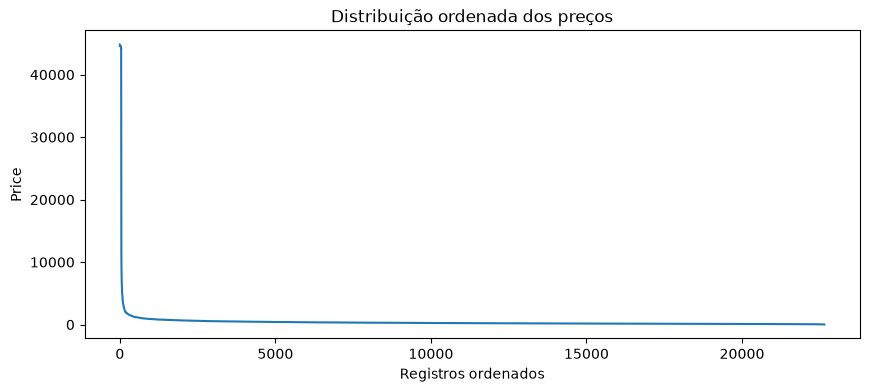

45    14475.0
42     8691.0
47     6107.0
46     2250.0
49     1500.0
48     1143.0
52      992.0
55      867.0
63      500.0
53      416.0
Name: price, dtype: float64

In [31]:
# ============================================================
# Distribuição dos maiores valores de price
# ============================================================

maiores_precos = dados["price"].sort_values(ascending=False)

display(maiores_precos.head(200))

# Ordena os preços do maior para o menor
precos_ordenados = dados["price"].sort_values(ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 4))
plt.plot(precos_ordenados)

plt.title("Distribuição ordenada dos preços")
plt.xlabel("Registros ordenados")
plt.ylabel("Price")

plt.show()

# Calcula a diferença entre preços consecutivos
diferencas = precos_ordenados - precos_ordenados.shift(-1)

# Mostra os maiores saltos
maiores_saltos = diferencas.sort_values(ascending=False).head(10)

display(maiores_saltos)

In [32]:
# ============================================================
# ANÁLISE - Maiores saltos entre preços consecutivos
# ============================================================

analise_saltos = pd.DataFrame({
    "price_atual": precos_ordenados,
    "proximo_price": precos_ordenados.shift(-1)
})

analise_saltos["diferenca"] = (
    analise_saltos["price_atual"] - analise_saltos["proximo_price"]
)

# Exibe os 10 maiores saltos
display(
    analise_saltos
    .sort_values("diferenca", ascending=False)
    .head(10)
)

,price_atual,proximo_price,diferenca
45,35475.0,21000.0,14475.0
42,44329.0,35638.0,8691.0
47,18750.0,12643.0,6107.0
46,21000.0,18750.0,2250.0
49,11500.0,10000.0,1500.0
48,12643.0,11500.0,1143.0
52,9992.0,9000.0,992.0
55,8427.0,7560.0,867.0
63,6500.0,6000.0,500.0
53,9000.0,8584.0,416.0


In [33]:
# ============================================================
# ANÁLISE - Comparação Bachcare x demais hosts
# ============================================================

# Bachcare
print("Bachcare:")
print(dados[dados["host_name"] == "Bachcare"]["price"].describe())

# Demais hosts
print("\nDemais hosts:")
print(dados[dados["host_name"] != "Bachcare"]["price"].describe())

print(
    "Bachcare com price > 10000:",
    (dados[dados["host_name"] == "Bachcare"]["price"] > 10000).sum()
)

print(
    "Demais hosts com price > 10000:",
    (dados[dados["host_name"] != "Bachcare"]["price"] > 10000).sum()
)

Bachcare:
count      806.000000
mean      2908.913151
std      10117.543127
min        145.000000
25%        311.000000
50%        384.500000
75%        518.750000
max      44825.000000
Name: price, dtype: float64

Demais hosts:
count    21843.000000
mean       324.085382
std        449.352364
min         14.000000
25%        138.000000
50%        220.000000
75%        380.000000
max      21000.000000
Name: price, dtype: float64
Bachcare com price > 10000: 46
Demais hosts com price > 10000: 4


In [34]:
# ============================================================
# ANÁLISE - Impacto dos registros anômalos da Bachcare
# ============================================================

# Identifica o grupo anômalo investigado
anomalias_bachcare = (
    (dados["host_name"] == "Bachcare") &
    (dados["price"] > 10000)
)

# Cria uma base temporária sem alterar o DataFrame original
dados_sem_anomalias = dados[~anomalias_bachcare]

print(f"Registros da base atual: {len(dados)}")
print(f"Registros anômalos analisados: {anomalias_bachcare.sum()}")
print(f"Registros sem as anomalias: {len(dados_sem_anomalias)}")

# Compara as estatísticas de price
comparacao = pd.DataFrame({
    "Com anomalias": dados["price"].describe(),
    "Sem anomalias": dados_sem_anomalias["price"].describe()
})

display(comparacao)


Registros da base atual: 22649
Registros anômalos analisados: 46
Registros sem as anomalias: 22603


,Com anomalias,Sem anomalias
count,22649.000000,22603.000000
mean,416.070511,327.485511
std,2015.562971,443.705479
min,14.000000,14.000000
25%,140.000000,140.000000
50%,229.000000,229.000000
75%,390.000000,389.000000
max,44825.000000,21000.000000


# 8. Demais outliers foram investigados e preservados

O IQR também apontou muitos valores extremos em outras variáveis, mas não havia evidência suficiente de erro.

- `minimum_nights`: 1.460 outliers; máximo 999
- `number_of_reviews`: 2.305; máximo 1.402
- `reviews_per_month`: 1.283; máximo 16,87
- `calculated_host_listings_count`: 4.265; máximo 1.760

Nos casos extremos, os valores eram coerentes com o contexto: estadias longas, anúncios muito avaliados, alta rotatividade ou hosts profissionais.

> **Outlier estatístico ≠ dado inválido.**  
> Quando não houve evidência de inconsistência, o registro foi mantido.

count    22649.000000
mean         2.186278
std         10.264545
min          1.000000
25%          1.000000
50%          2.000000
75%          2.000000
max        999.000000
Name: minimum_nights, dtype: float64


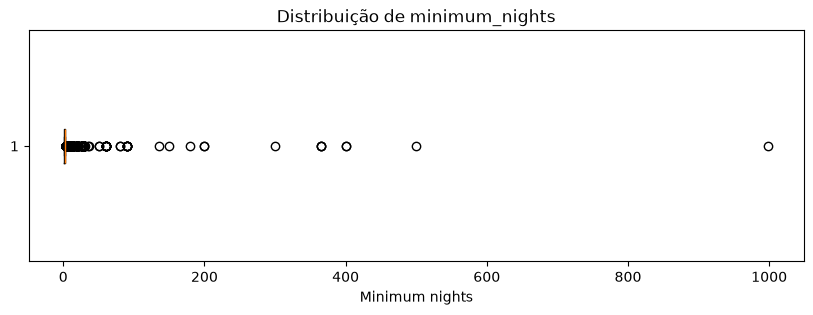

Q1: 1.00
Q3: 2.00
Limite inferior: -0.50
Limite superior: 3.50

Quantidade de outliers: 1460
Percentual de outliers: 6.45%


In [35]:
# ============================================================
# Análise de outliers - minimum_nights
# ============================================================

# Estatísticas descritivas
print(dados["minimum_nights"].describe())

# Boxplot para análise visual
plt.figure(figsize=(10,3))
plt.boxplot(dados["minimum_nights"], orientation="horizontal")

plt.title("Distribuição de minimum_nights")
plt.xlabel("Minimum nights")
plt.show()


# ============================================================
# DEFINIÇÃO DOS LIMITES (IQR)
# ============================================================

Q1 = dados["minimum_nights"].quantile(0.25)
Q3 = dados["minimum_nights"].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"Limite inferior: {limite_inferior:.2f}")
print(f"Limite superior: {limite_superior:.2f}")


# Identifica os outliers
outliers_minimum_nights = dados[
    (dados["minimum_nights"] < limite_inferior) |
    (dados["minimum_nights"] > limite_superior)
]

print(f"\nQuantidade de outliers: {len(outliers_minimum_nights)}")
print(
    f"Percentual de outliers: "
    f"{(len(outliers_minimum_nights) / len(dados)) * 100:.2f}%"
)

In [36]:
# ============================================================
# ANÁLISE - minimum_nights por faixas
# ============================================================

print("Minimum nights >= 4:   ", (dados["minimum_nights"] >= 4).sum())
print("Minimum nights > 7:    ", (dados["minimum_nights"] > 7).sum())
print("Minimum nights > 30:   ", (dados["minimum_nights"] > 30).sum())
print("Minimum nights > 90:   ", (dados["minimum_nights"] > 90).sum())
print("Minimum nights > 180:  ", (dados["minimum_nights"] > 180).sum())
print("Minimum nights > 365:  ", (dados["minimum_nights"] > 365).sum())

Minimum nights >= 4:    1460
Minimum nights > 7:     211
Minimum nights > 30:    38
Minimum nights > 90:    13
Minimum nights > 180:   10
Minimum nights > 365:   4


In [37]:
# ============================================================
# ANÁLISE - Valores extremos de minimum_nights
# ============================================================

minimum_nights_extremos = dados[
    dados["minimum_nights"] > 90
][
    ["name",
     "host_name",
     "neighbourhood_group",
     "room_type",
     "price",
     "minimum_nights",
     "number_of_reviews",
     "reviews_per_month",
     "availability_365"]
].sort_values("minimum_nights", ascending=False)

display(minimum_nights_extremos)

,name,host_name,neighbourhood_group,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,availability_365
15954,"Fantail Bush Chalet, bush & golf on the doorstep",Heidi,Auckland,Entire home/apt,219.0,999.0,163,2.54,177
17912,Nice and Convenient place:),Po,Auckland,Private room,48.0,500.0,3,0.05,297
17910,Wynyard Quarter Townhouse,Brendan And Natalie,Auckland,Entire home/apt,324.0,400.0,0,0.00,334
16490,Beautiful home..8 minute walk to Browns Bay beach,Alecia,Auckland,Entire home/apt,180.0,400.0,2,0.03,174
11183,Whole House Amazing 3 bedroom house,MiniClean,Tauranga City,Entire home/apt,300.0,365.0,3,0.12,365
21342,Walnut on Russell (accessible if requested),Daniel,Queenstown-Lakes District,Entire home/apt,350.0,365.0,3,2.73,196
11318,1 bedroom Available in Shared House,MiniClean,Tauranga City,Private room,291.0,365.0,0,0.00,365
19920,Whole apartment for many guests,Young Duck,Auckland,Entire home/apt,460.0,300.0,0,0.00,365
4178,"Large Home with Mountain Views, Linen and WIFI",Sue,Ruapehu District,Entire home/apt,1000.0,200.0,65,0.59,89
12954,Room for rent. Great location.,Kathryn,Palmerston North City,Private room,95.0,200.0,0,0.00,364


In [38]:
# ============================================================
# ANÁLISE - Frequência dos valores extremos de minimum_nights
# ============================================================

frequencia_minimum_nights = (
    dados[dados["minimum_nights"] > 30]["minimum_nights"]
    .value_counts()
    .sort_index(ascending=False)
)

display(frequencia_minimum_nights)

minimum_nights
999.0     1
500.0     1
400.0     2
365.0     3
300.0     1
200.0     2
180.0     1
150.0     1
136.0     1
90.0      7
80.0      2
60.0     11
50.0      2
36.0      1
35.0      1
31.0      1
Name: count, dtype: int64

count    22649.000000
mean        58.744889
std        103.028770
min          0.000000
25%          3.000000
50%         19.000000
75%         67.000000
max       1402.000000
Name: number_of_reviews, dtype: float64


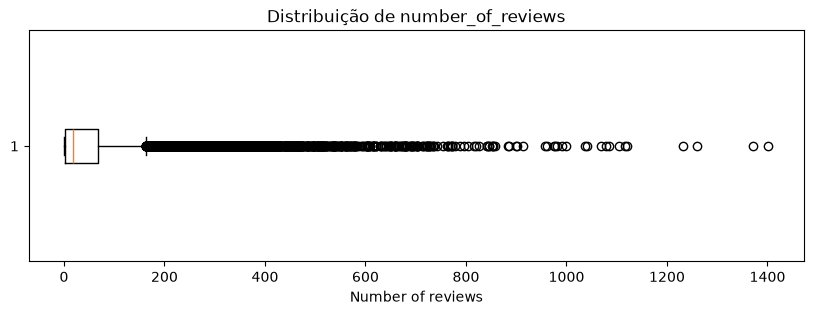

Q1: 3.00
Q3: 67.00
Limite inferior: -93.00
Limite superior: 163.00

Quantidade de outliers: 2305
Percentual de outliers: 10.18%


In [39]:
# ============================================================
# Análise de outliers - number_of_reviews
# ============================================================

# Estatísticas descritivas
print(dados["number_of_reviews"].describe())

# Boxplot para análise visual
plt.figure(figsize=(10,3))
plt.boxplot(dados["number_of_reviews"], orientation="horizontal")

plt.title("Distribuição de number_of_reviews")
plt.xlabel("Number of reviews")
plt.show()


# ============================================================
# DEFINIÇÃO DOS LIMITES (IQR)
# ============================================================

Q1 = dados["number_of_reviews"].quantile(0.25)
Q3 = dados["number_of_reviews"].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"Limite inferior: {limite_inferior:.2f}")
print(f"Limite superior: {limite_superior:.2f}")


# Identifica os outliers
outliers_reviews = dados[
    (dados["number_of_reviews"] < limite_inferior) |
    (dados["number_of_reviews"] > limite_superior)
]

print(f"\nQuantidade de outliers: {len(outliers_reviews)}")
print(
    f"Percentual de outliers: "
    f"{(len(outliers_reviews) / len(dados)) * 100:.2f}%"
)

In [40]:
# ============================================================
# ANÁLISE - number_of_reviews por faixas
# ============================================================

print("Reviews > 163:  ", (dados["number_of_reviews"] > 163).sum())
print("Reviews > 250:  ", (dados["number_of_reviews"] > 250).sum())
print("Reviews > 500:  ", (dados["number_of_reviews"] > 500).sum())
print("Reviews > 750:  ", (dados["number_of_reviews"] > 750).sum())
print("Reviews > 1000: ", (dados["number_of_reviews"] > 1000).sum())

Reviews > 163:   2305
Reviews > 250:   1170
Reviews > 500:   233
Reviews > 750:   47
Reviews > 1000:  12


In [41]:
# ============================================================
# ANÁLISE - Valores extremos de number_of_reviews
# ============================================================

reviews_extremos = dados[
    dados["number_of_reviews"] > 1000
][
    ["name",
     "host_name",
     "neighbourhood_group",
     "room_type",
     "number_of_reviews",
     "last_review",
     "reviews_per_month",
     "availability_365"]
].sort_values("number_of_reviews", ascending=False)

display(reviews_extremos)

,name,host_name,neighbourhood_group,room_type,number_of_reviews,last_review,reviews_per_month,availability_365
15577,"Airport Studio, King bed. NO CLEANING FEE.",Sharon,Christchurch City,Entire home/apt,1402,2024-12-21,13.31,281
328,lazy porch studio,Lou,Christchurch City,Entire home/apt,1372,2024-12-27,11.82,299
14932,The Cowshed,Angela,Marlborough District,Entire home/apt,1260,2025-01-03,12.24,315
4016,Airport Haven with Netflix. NO CLEANING FEE.,Sharon,Christchurch City,Entire home/apt,1231,2024-12-14,14.20,279
13460,"On top of Mt Victoria, Wellington Brand New St...",Karen,Wellington City,Entire home/apt,1120,2024-12-30,11.61,108
3109,Stylish loft 10-15 mins to city/ferry with par...,Aude,Wellington City,Private room,1116,2024-12-23,12.17,0
21389,The cosy cabin with stunning view and private spa,Nancy,Queenstown-Lakes District,Entire home/apt,1104,2024-12-22,11.13,1
15899,Private en-suite apartment with private parking.,Ann & Kapi,Christchurch City,Entire home/apt,1084,2024-12-21,10.41,5
21371,Independant warm room & ensuite - no cleaning fee,Lucy,Queenstown-Lakes District,Private room,1079,2024-12-21,10.18,279
3204,Home away from home Khandallah,Jennifer,Wellington City,Private room,1069,2025-01-05,9.88,70


count    22649.000000
mean         1.635591
std          1.886946
min          0.000000
25%          0.290000
50%          1.000000
75%          2.270000
max         16.870000
Name: reviews_per_month, dtype: float64


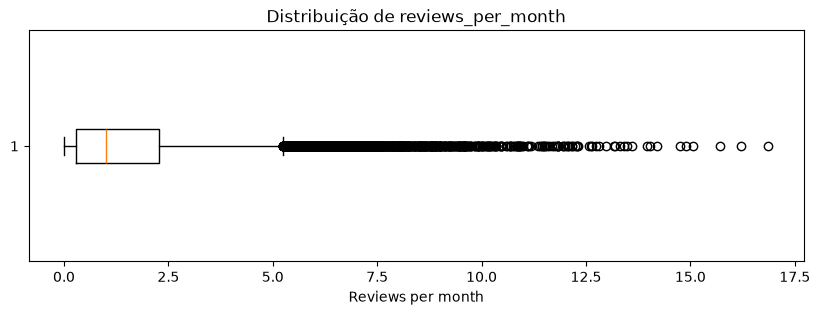

Q1: 0.29
Q3: 2.27
Limite inferior: -2.68
Limite superior: 5.24

Quantidade de outliers: 1283
Percentual de outliers: 5.66%


In [42]:
# ============================================================
# Análise de outliers - reviews_per_month
# ============================================================

# Estatísticas descritivas
print(dados["reviews_per_month"].describe())

# Boxplot para análise visual
plt.figure(figsize=(10,3))
plt.boxplot(dados["reviews_per_month"], orientation="horizontal")

plt.title("Distribuição de reviews_per_month")
plt.xlabel("Reviews per month")
plt.show()


# ============================================================
# DEFINIÇÃO DOS LIMITES (IQR)
# ============================================================

Q1 = dados["reviews_per_month"].quantile(0.25)
Q3 = dados["reviews_per_month"].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"Limite inferior: {limite_inferior:.2f}")
print(f"Limite superior: {limite_superior:.2f}")


# Identifica os outliers
outliers_reviews_month = dados[
    (dados["reviews_per_month"] < limite_inferior) |
    (dados["reviews_per_month"] > limite_superior)
]

print(f"\nQuantidade de outliers: {len(outliers_reviews_month)}")
print(
    f"Percentual de outliers: "
    f"{(len(outliers_reviews_month) / len(dados)) * 100:.2f}%"
)

In [43]:
# ============================================================
# ANÁLISE - reviews_per_month por faixas
# ============================================================

print("Reviews/mês > 5.24: ", (dados["reviews_per_month"] > 5.24).sum())
print("Reviews/mês > 7.5:  ", (dados["reviews_per_month"] > 7.5).sum())
print("Reviews/mês > 10:   ", (dados["reviews_per_month"] > 10).sum())
print("Reviews/mês > 12.5: ", (dados["reviews_per_month"] > 12.5).sum())
print("Reviews/mês > 15:   ", (dados["reviews_per_month"] > 15).sum())

Reviews/mês > 5.24:  1283
Reviews/mês > 7.5:   398
Reviews/mês > 10:    98
Reviews/mês > 12.5:  21
Reviews/mês > 15:    4


In [44]:
# ============================================================
# ANÁLISE - Valores extremos de reviews_per_month
# ============================================================

reviews_month_extremos = dados[
    dados["reviews_per_month"] > 15
][
    ["name",
     "host_name",
     "room_type",
     "minimum_nights",
     "number_of_reviews",
     "last_review",
     "reviews_per_month",
     "availability_365"]
].sort_values("reviews_per_month", ascending=False)

display(reviews_month_extremos)


,name,host_name,room_type,minimum_nights,number_of_reviews,last_review,reviews_per_month,availability_365
9940,Violet's,Violeta,Entire home/apt,1.0,884,2025-01-03,16.87,222
7070,THE BIRD'S NEST - Secluded getaway!,Jo,Entire home/apt,1.0,53,2025-01-04,16.22,116
9842,2-Mile Bay Hideaway,Crystal,Entire home/apt,1.0,274,2024-12-25,15.72,156
5172,Jimmy's Retreat,Amanda,Entire home/apt,1.0,537,2025-01-02,15.07,309


count    22649.000000
mean        74.240408
std        325.036612
min          1.000000
25%          1.000000
50%          2.000000
75%          6.000000
max       1760.000000
Name: calculated_host_listings_count, dtype: float64


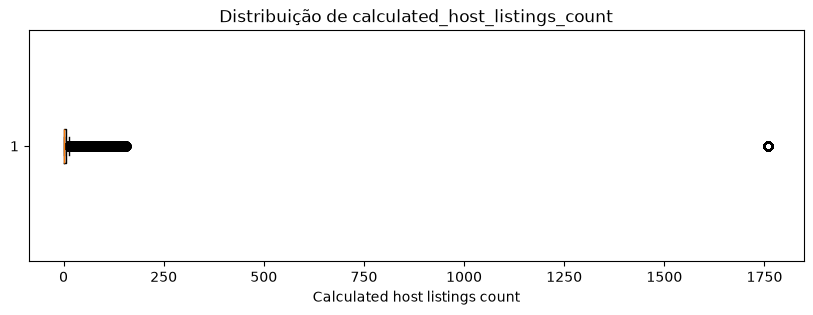

Q1: 1.00
Q3: 6.00
Limite inferior: -6.50
Limite superior: 13.50

Quantidade de outliers: 4265
Percentual de outliers: 18.83%


In [45]:
# ============================================================
# Análise de outliers - calculated_host_listings_count
# ============================================================

# Estatísticas descritivas
print(dados["calculated_host_listings_count"].describe())

# Boxplot para análise visual
plt.figure(figsize=(10,3))
plt.boxplot(
    dados["calculated_host_listings_count"],
    orientation="horizontal"
)

plt.title("Distribuição de calculated_host_listings_count")
plt.xlabel("Calculated host listings count")
plt.show()


# ============================================================
# DEFINIÇÃO DOS LIMITES (IQR)
# ============================================================

Q1 = dados["calculated_host_listings_count"].quantile(0.25)
Q3 = dados["calculated_host_listings_count"].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"Limite inferior: {limite_inferior:.2f}")
print(f"Limite superior: {limite_superior:.2f}")


# Identifica os outliers
outliers_host_listings = dados[
    (dados["calculated_host_listings_count"] < limite_inferior) |
    (dados["calculated_host_listings_count"] > limite_superior)
]

print(f"\nQuantidade de outliers: {len(outliers_host_listings)}")
print(
    f"Percentual de outliers: "
    f"{(len(outliers_host_listings) / len(dados)) * 100:.2f}%"
)

In [46]:
# ============================================================
# ANÁLISE - Maiores hosts por quantidade de anúncios
# ============================================================

hosts_listings = (
    dados[
        ["host_name", "calculated_host_listings_count"]
    ]
    .drop_duplicates()
    .sort_values(
        "calculated_host_listings_count",
        ascending=False
    )
)

display(hosts_listings.head(20))

# Quantidade de registros da base por host
frequencia_hosts = dados["host_name"].value_counts()

display(frequencia_hosts.head(20))

,host_name,calculated_host_listings_count
180,Bachcare,1760.0
10194,Eric,157.0
15060,Hanmer Holiday Homes,153.0
17170,Stefan,151.0
6,Ohana,145.0
17428,Stay Waiheke,138.0
7692,Hosts,132.0
262,Bcr Property,130.0
14079,"Mara, Ola, Jarrod & Rob.",130.0
1,Carebnb,120.0


host_name
Bachcare    806
Sarah       179
Amy         138
Lisa        137
Karen       119
John        111
David       107
Kate        101
Anna        100
Peter        91
Julie        90
Kim          90
Paul         89
Helen        87
Mark         86
Jane         86
Angela       83
Emma         83
Jonathan     81
Rebecca      81
Name: count, dtype: int64

# 9. Validações adicionais: disponibilidade, localização e categorias

### `availability_365`
Todos os valores estavam no domínio esperado **0–365**.

### Coordenadas
Seis longitudes próximas de -176° pareciam isoladas, mas pertenciam ao **Chatham Islands Territory** — portanto eram geograficamente legítimas.

### Categóricas
- `room_type`: 4 categorias válidas
- `neighbourhood_group`: 67 categorias
- `neighbourhood`: 209 categorias
- 161 registros de `neighbourhood` tinham espaços extras; aplicamos `strip()` como padronização
- nomes como `Central Ward` aparecem em diferentes distritos: não eram inconsistências

> A interpretação do domínio evitou corrigir dados válidos apenas por parecerem atípicos.

count    22649.000000
mean       197.825908
std        121.933629
min          0.000000
25%         84.000000
50%        205.000000
75%        317.000000
max        365.000000
Name: availability_365, dtype: float64


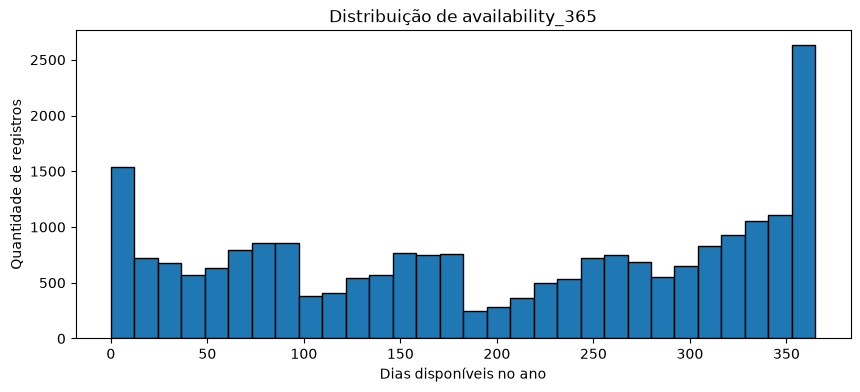

In [47]:
# ============================================================
# Análise de availability_365
# ============================================================

# Estatísticas descritivas
print(dados["availability_365"].describe())

# Histograma
plt.figure(figsize=(10,4))

plt.hist(
    dados["availability_365"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribuição de availability_365")
plt.xlabel("Dias disponíveis no ano")
plt.ylabel("Quantidade de registros")

plt.show()

In [48]:
# ============================================================
# ANÁLISE - Extremos de availability_365
# ============================================================

disponibilidade_zero = (dados["availability_365"] == 0).sum()
disponibilidade_total = (dados["availability_365"] == 365).sum()

print(f"Disponibilidade = 0: {disponibilidade_zero}")
print(
    f"Percentual: "
    f"{disponibilidade_zero / len(dados) * 100:.2f}%"
)

print(f"\nDisponibilidade = 365: {disponibilidade_total}")
print(
    f"Percentual: "
    f"{disponibilidade_total / len(dados) * 100:.2f}%"
)

Disponibilidade = 0: 497
Percentual: 2.19%

Disponibilidade = 365: 668
Percentual: 2.95%


In [49]:
# ============================================================
# Análise das coordenadas geográficas
# ============================================================

print("Latitude mínima: ", dados["latitude"].min())
print("Latitude máxima: ", dados["latitude"].max())

print("Longitude mínima:", dados["longitude"].min())
print("Longitude máxima:", dados["longitude"].max())

Latitude mínima:  -46.9067295596263
Latitude máxima:  -34.51571
Longitude mínima: -176.56121
Longitude máxima: 178.43072


In [50]:
# ============================================================
# ANÁLISE - Coordenadas geográficas extremas
# ============================================================

# Registros com longitude negativa
longitude_negativa = dados[dados["longitude"] < 0]

print(
    f"Registros com longitude negativa: "
    f"{len(longitude_negativa)}"
)

display(
    longitude_negativa[
        ["name",
         "neighbourhood_group",
         "neighbourhood",
         "latitude",
         "longitude"]
    ].sort_values("longitude")
)

Registros com longitude negativa: 6


,name,neighbourhood_group,neighbourhood,latitude,longitude
1017,Travellers Rest Chatham Islands Room 33,Chatham Islands Territory,Area Outside Ward,-43.95278,-176.56121
1016,Travellers RestChatham Islands Unit 36/37,Chatham Islands Territory,Area Outside Ward,-43.95283,-176.56056
22471,Travellers Rest Chatham Islands Unit 35,Chatham Islands Territory,Area Outside Ward,-43.95106,-176.55920
1208,Travellers Rest Chatham Islands Room 32,Chatham Islands Territory,Area Outside Ward,-43.95267,-176.55899
1018,Awatotara Cottage \n: self-contained 3 bedroom,Chatham Islands Territory,Area Outside Ward,-44.00491,-176.53992
1019,Owenga Seaside Container Cottage,Chatham Islands Territory,Area Outside Ward,-44.02834,-176.35149


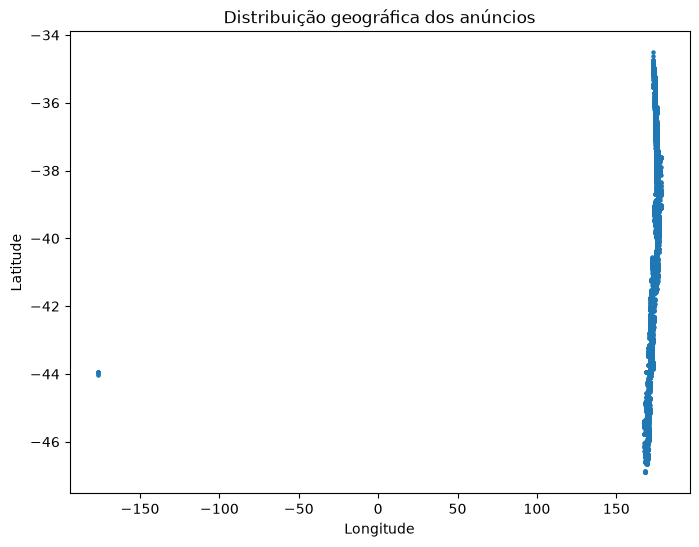

In [51]:
# Distribuição geográfica dos anúncios
plt.figure(figsize=(8,6))

plt.scatter(
    dados["longitude"],
    dados["latitude"],
    s=5
)

plt.title("Distribuição geográfica dos anúncios")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.show()

In [52]:
# ============================================================
# Análise das variáveis categóricas
# ============================================================

# Quantidade de valores distintos
print("Valores distintos por atributo categórico:\n")

print("room_type:", dados["room_type"].nunique())
print("neighbourhood_group:", dados["neighbourhood_group"].nunique())
print("neighbourhood:", dados["neighbourhood"].nunique())
print("host_name:", dados["host_name"].nunique())

Valores distintos por atributo categórico:

room_type: 4
neighbourhood_group: 67
neighbourhood: 209
host_name: 5398


In [53]:
# ============================================================
# ANÁLISE - Valores de room_type
# ============================================================

print("Categorias de room_type:\n")

print(dados["room_type"].value_counts())

print("\nDistribuição percentual:\n")

print(
    dados["room_type"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Categorias de room_type:

room_type
Entire home/apt    18479
Private room        4029
Hotel room            99
Shared room           42
Name: count, dtype: int64

Distribuição percentual:

room_type
Entire home/apt    81.59
Private room       17.79
Hotel room          0.44
Shared room         0.19
Name: proportion, dtype: float64


In [54]:
# Verifica possíveis espaços antes ou depois das categorias

room_type_espacos = (
    dados["room_type"] != dados["room_type"].str.strip()
).sum()

print(
    "Registros de room_type com espaços no início/final:",
    room_type_espacos
)

Registros de room_type com espaços no início/final: 0


In [55]:
# ============================================================
# ANÁLISE - neighbourhood_group
# ============================================================

# Frequência das categorias
frequencia_neighbourhood_group = (
    dados["neighbourhood_group"]
    .value_counts()
)

display(frequencia_neighbourhood_group)

# Verifica espaços no início/final
espacos_neighbourhood_group = (
    dados["neighbourhood_group"]
    != dados["neighbourhood_group"].str.strip()
).sum()

print(
    "\nRegistros com espaços no início/final:",
    espacos_neighbourhood_group
)

# Categorias com poucos registros
print("\nCategorias com até 5 registros:")

display(
    frequencia_neighbourhood_group[
        frequencia_neighbourhood_group <= 5
    ]
)

neighbourhood_group
Auckland                      4438
Queenstown-Lakes District     2567
Christchurch City             1414
Tauranga City                 1043
Thames-Coromandel District     890
                              ... 
Stratford District              21
Waimate District                17
Gore District                   17
Chatham Islands Territory        6
Kawerau District                 4
Name: count, Length: 67, dtype: int64


Registros com espaços no início/final: 0

Categorias com até 5 registros:


neighbourhood_group
Kawerau District    4
Name: count, dtype: int64

In [56]:
# ============================================================
# ANÁLISE - neighbourhood
# ============================================================

frequencia_neighbourhood = dados["neighbourhood"].value_counts()

print(f"Quantidade de categorias: {dados['neighbourhood'].nunique()}")

# Verifica espaços no início/final
espacos_neighbourhood = (
    dados["neighbourhood"]
    != dados["neighbourhood"].str.strip()
).sum()

print(
    "Registros com espaços no início/final:",
    espacos_neighbourhood
)

# Categorias menos frequentes
print("\n10 categorias menos frequentes:")

display(
    frequencia_neighbourhood.tail(10)
)

Quantidade de categorias: 209
Registros com espaços no início/final: 161

10 categorias menos frequentes:


neighbourhood
Levin Ward                      3
Hakataramea-Waihaorunga Ward    2
Ohura Ward                      2
Flaxmere Ward                   2
Waikaka Ward                    2
Eltham-Kaponga Ward             1
Waipa Ward                      1
Wharepuhunga Ward               1
Te Kuiti Ward                   1
Clutha Valley Ward              1
Name: count, dtype: int64

In [57]:
# ============================================================
# ANÁLISE - Impacto dos espaços em neighbourhood
# ============================================================

print(
    "Categorias antes da correção:",
    dados["neighbourhood"].nunique()
)

print(
    "Categorias após remover espaços:",
    dados["neighbourhood"].str.strip().nunique()
)

Categorias antes da correção: 209
Categorias após remover espaços: 209


In [58]:
# Registros com espaços no início/final

neighbourhood_com_espacos = dados[
    dados["neighbourhood"] != dados["neighbourhood"].str.strip()
]

display(
    neighbourhood_com_espacos[
        ["neighbourhood_group", "neighbourhood"]
    ].drop_duplicates()
)

,neighbourhood_group,neighbourhood
12020,Whakatane District,Rangitāiki Ward
12123,Whakatane District,Whakatāne-Ōhope Ward
12312,Whakatane District,Tāneatua-Waimana Ward
12876,Kapiti Coast District,Ōtaki Ward


In [59]:
# Padronização dos valores de neighbourhood
dados["neighbourhood"] = dados["neighbourhood"].str.strip()

In [60]:
print(
    "Registros com espaços após padronização:",
    (dados["neighbourhood"] != dados["neighbourhood"].str.strip()).sum()
)

print(
    "Quantidade de categorias:",
    dados["neighbourhood"].nunique()
)

Registros com espaços após padronização: 0
Quantidade de categorias: 209


In [61]:
# ============================================================
# ANÁLISE - Relação neighbourhood x neighbourhood_group
# ============================================================

# Conta quantos neighbourhood_group diferentes existem
# para cada neighbourhood

grupos_por_neighbourhood = (
    dados.groupby("neighbourhood")["neighbourhood_group"]
    .nunique()
)

# Seleciona neighbourhood associados a mais de um grupo
inconsistencias_neighbourhood = grupos_por_neighbourhood[
    grupos_por_neighbourhood > 1
]

print(
    "Neighbourhood associados a mais de um neighbourhood_group:",
    len(inconsistencias_neighbourhood)
)

display(inconsistencias_neighbourhood)

Neighbourhood associados a mais de um neighbourhood_group: 9


neighbourhood
Ahuriri Ward          2
Area Outside Ward    12
Central Ward          4
East Ward             2
Eastern Ward          3
Northern Ward         4
Southern Ward         3
West Ward             2
Western Ward          2
Name: neighbourhood_group, dtype: int64

In [62]:
# ============================================================
# ANÁLISE - neighbourhood repetido entre diferentes grupos
# ============================================================

neighbourhood_multiplos = inconsistencias_neighbourhood.index

relacoes_multiplas = (
    dados[
        dados["neighbourhood"].isin(neighbourhood_multiplos)
    ][
        ["neighbourhood", "neighbourhood_group"]
    ]
    .drop_duplicates()
    .sort_values(
        ["neighbourhood", "neighbourhood_group"]
    )
)

display(relacoes_multiplas)

,neighbourhood,neighbourhood_group
9194,Ahuriri Ward,Napier City
1020,Ahuriri Ward,Waitaki District
13583,Area Outside Ward,Carterton District
1016,Area Outside Ward,Chatham Islands Territory
7269,Area Outside Ward,Dunedin City
15770,Area Outside Ward,Invercargill City
3615,Area Outside Ward,Kaikoura District
12322,Area Outside Ward,Kawerau District
13513,Area Outside Ward,Masterton District
14406,Area Outside Ward,Nelson City


In [63]:
# ============================================================
# ANÁLISE - Consistência entre host_id e host_name
# ============================================================

# Valores ausentes
print("host_id ausentes:", dados["host_id"].isna().sum())
print("host_name ausentes:", dados["host_name"].isna().sum())

# Quantidade de identificadores e nomes distintos
print("\nhost_id distintos:", dados["host_id"].nunique())
print("host_name distintos:", dados["host_name"].nunique())

# Verifica quantos nomes diferentes estão associados a cada host_id
nomes_por_host = (
    dados.groupby("host_id")["host_name"]
    .nunique()
)

hosts_multiplos_nomes = nomes_por_host[
    nomes_por_host > 1
]

print(
    "\nhost_id associados a mais de um host_name:",
    len(hosts_multiplos_nomes)
)

host_id ausentes: 0
host_name ausentes: 14

host_id distintos: 15362
host_name distintos: 5398

host_id associados a mais de um host_name: 0


In [64]:
# ============================================================
# ANÁLISE - host_name ausente
# ============================================================

host_name_ausente = dados[
    dados["host_name"].isna()
][
    ["host_id", "host_name", "name",
     "neighbourhood_group", "room_type", "price"]
]

display(host_name_ausente)

,host_id,host_name,name,neighbourhood_group,room_type,price
1678,23434757,NaN,"Sun Peaks Villa | Luxury, style & great amenities",Queenstown-Lakes District,Entire home/apt,1428.0
1835,23434757,NaN,Mountain Vista | Fantastic outdoor living,Queenstown-Lakes District,Entire home/apt,1281.0
20524,23434757,NaN,Willow Waters | Lakeside luxury living,Queenstown-Lakes District,Entire home/apt,2090.0
20726,23434757,NaN,Q1 Luxury Central Apartment,Queenstown-Lakes District,Entire home/apt,1501.0
20769,23434757,NaN,Castle Cliff Lodge | Spa Pool + Sauna | Games ...,Queenstown-Lakes District,Entire home/apt,4116.0
20823,23434757,NaN,180 Park | Lakefront Masterpiece,Queenstown-Lakes District,Entire home/apt,11500.0
20880,23434757,NaN,Bel Lago | Luxury home | Every room with a view,Queenstown-Lakes District,Entire home/apt,1750.0
20888,23434757,NaN,Livin' on Lake Time | Waterfront w/ stunning v...,Queenstown-Lakes District,Entire home/apt,1330.0
20894,23434757,NaN,Upper Gardens - only a 4 minute walk to town,Queenstown-Lakes District,Entire home/apt,649.0
20922,23434757,NaN,Lakehouse Joela - award winning luxury home,Queenstown-Lakes District,Entire home/apt,3650.0


In [65]:
ids_sem_nome = dados.loc[
    dados["host_name"].isna(),
    "host_id"
]

display(
    dados[dados["host_id"].isin(ids_sem_nome)][
        ["host_id", "host_name"]
    ].drop_duplicates()
)

,host_id,host_name
1678,23434757,NaN


In [66]:
# ============================================================
# ANÁLISE - name
# ============================================================

print("Registros com name ausente:", dados["name"].isna().sum())

print(
    "Percentual:",
    f"{dados['name'].isna().sum() / len(dados) * 100:.2f}%"
)

print(
    "Nomes distintos:",
    dados["name"].nunique()
)

Registros com name ausente: 0
Percentual: 0.00%
Nomes distintos: 22321


In [67]:
# Verifica strings vazias ou contendo somente espaços

name_vazio = (
    dados["name"]
    .fillna("")
    .str.strip()
    .eq("")
    .sum()
)

print("Registros com name vazio ou ausente:", name_vazio)

Registros com name vazio ou ausente: 0


In [68]:
# ============================================================
# Remoção das anomalias identificadas em price
# ============================================================

# Quantidade de registros antes da remoção
registros_antes = len(dados)

# ------------------------------------------------------------
# Identifica os registros considerados anômalos
# Critério definido após análise da distribuição dos preços
# ------------------------------------------------------------

price_anomalos = dados[
    (dados["host_name"] == "Bachcare") &
    (dados["price"] > 10000)
]

print("Registros antes da remoção:", registros_antes)
print("Registros identificados para remoção:", len(price_anomalos))


# ------------------------------------------------------------
# Remove os registros identificados
# ------------------------------------------------------------

dados = dados.drop(index=price_anomalos.index)

# Reorganiza o índice após a remoção
dados = dados.reset_index(drop=True)


# ------------------------------------------------------------
# Validação da remoção
# ------------------------------------------------------------

registros_depois = len(dados)

print("\nRegistros removidos:", registros_antes - registros_depois)
print("Registros restantes:", registros_depois)

print("\nValidação de price:")
print("Valores ausentes:", dados["price"].isna().sum())
print("Menor valor:", dados["price"].min())
print("Maior valor:", dados["price"].max())

print(
    "Registros Bachcare com price > 10000:",
    (
        (dados["host_name"] == "Bachcare") &
        (dados["price"] > 10000)
    ).sum()
)

print(
    "Registros de outros hosts com price > 10000:",
    (
        (dados["host_name"] != "Bachcare") &
        (dados["price"] > 10000)
    ).sum()
)


# ------------------------------------------------------------
# Validação da estrutura final da base
# ------------------------------------------------------------

print("\nDimensão atual da base:")
print(dados.shape)

print("\nInformações da base:")
dados.info()

Registros antes da remoção: 22649
Registros identificados para remoção: 46

Registros removidos: 46
Registros restantes: 22603

Validação de price:
Valores ausentes: 0
Menor valor: 14.0
Maior valor: 21000.0
Registros Bachcare com price > 10000: 0
Registros de outros hosts com price > 10000: 4

Dimensão atual da base:
(22603, 16)

Informações da base:
<class 'pandas.DataFrame'>
RangeIndex: 22603 entries, 0 to 22602
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   id                              22603 non-null  float64       
 1   name                            22603 non-null  str           
 2   host_id                         22603 non-null  str           
 3   host_name                       22589 non-null  str           
 4   neighbourhood_group             22603 non-null  str           
 5   neighbourhood                   22603 non-null  str           
 6   

# 10. Resultado da limpeza

### Base final tratada
> **22.603 registros × 16 atributos**

Principais resultados:
- 0 duplicidades
- 0 IDs duplicados
- 0 ausentes em `price`
- 0 ausentes em `reviews_per_month`
- 14 ausentes em `host_name`, mantidos conscientemente
- 2.483 ausentes em `last_review`, relacionados a anúncios sem avaliações

### Efeito sobre `price`
A remoção das 46 anomalias reduziu fortemente média e desvio padrão, enquanto mediana e quartis permaneceram praticamente estáveis.

> A limpeza removeu problemas específicos sem descaracterizar a distribuição central da base.

In [69]:
# ============================================================
# Validação final da base tratada
# ============================================================

# Dimensão final
print("Dimensão final da base:")
print(f"{dados.shape[0]} registros x {dados.shape[1]} atributos")


# ------------------------------------------------------------
# Valores ausentes
# ------------------------------------------------------------

qtde_linhas = len(dados)
qtde_presentes = dados.count()
qtde_ausentes = dados.isna().sum()
perc_ausentes = (qtde_ausentes / qtde_linhas) * 100

ausentes_final = pd.DataFrame({
    "Qtde Linhas": qtde_linhas,
    "Qtde registros": qtde_presentes,
    "Qtde Ausentes": qtde_ausentes,
    "Percentual": perc_ausentes
})

print("\nValores ausentes após o tratamento:")
display(ausentes_final)


# ------------------------------------------------------------
# Estatísticas descritivas finais
# ------------------------------------------------------------

print("\nEstatísticas descritivas da base tratada:")
display(dados.describe())


# ------------------------------------------------------------
# Registros duplicados
# ------------------------------------------------------------

print(
    "\nRegistros totalmente duplicados:",
    dados.duplicated().sum()
)

print(
    "IDs duplicados:",
    dados["id"].duplicated().sum()
)

Dimensão final da base:
22603 registros x 16 atributos

Valores ausentes após o tratamento:


,Qtde Linhas,Qtde registros,Qtde Ausentes,Percentual
id,22603,22603,0,0.000000
name,22603,22603,0,0.000000
host_id,22603,22603,0,0.000000
host_name,22603,22589,14,0.061939
neighbourhood_group,22603,22603,0,0.000000
neighbourhood,22603,22603,0,0.000000
latitude,22603,22603,0,0.000000
longitude,22603,22603,0,0.000000
room_type,22603,22603,0,0.000000
price,22603,22603,0,0.000000



Estatísticas descritivas da base tratada:


,id,latitude,longitude,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
count,2.260300e+04,22603.000000,22603.000000,22603.000000,22603.000000,22603.000000,20120,22603.000000,22603.000000,22603.000000
mean,5.978281e+17,-40.017487,173.618979,327.485511,2.188692,58.858382,2024-09-11 13:09:03.936381,1.638629,70.809671,197.487856
min,4.607100e+04,-46.906730,-176.561210,14.000000,1.000000,0.000000,2013-04-04 00:00:00,0.000000,1.000000,0.000000
25%,3.856771e+07,-43.519187,172.635463,140.000000,1.000000,3.000000,2024-10-27 00:00:00,0.290000,1.000000,84.000000
50%,7.563264e+17,-39.057400,174.739960,229.000000,2.000000,19.000000,2024-12-18 00:00:00,1.000000,2.000000,204.000000
75%,1.091001e+18,-36.914132,175.428740,389.000000,2.000000,68.000000,2024-12-31 00:00:00,2.270000,6.000000,317.000000
max,1.326303e+18,-34.515710,178.430720,21000.000000,999.000000,1402.000000,2025-01-05 00:00:00,16.870000,1760.000000,365.000000
std,5.277189e+17,3.284382,6.235453,443.705479,10.274845,103.102594,NaN,1.887640,316.335888,121.826902



Registros totalmente duplicados: 0
IDs duplicados: 0


# 11. O que parece estar associado a `price`?

### Variáveis numéricas — Spearman
| Atributo | Correlação |
|---|---:|
| `minimum_nights` | **0,305** |
| `reviews_per_month` | **-0,263** |
| `calculated_host_listings_count` | **0,237** |
| `number_of_reviews` | **-0,221** |

Pearson foi mais baixo, sugerindo relações que não são estritamente lineares.

### Variáveis categóricas — Kruskal-Wallis
Todos os testes apresentaram `p < 0,05`.

| Atributo | ε² |
|---|---:|
| `neighbourhood` | **0,2126** |
| `room_type` | **0,2079** |
| `neighbourhood_group` | **0,1751** |

> Tipo de acomodação e localização apresentam associação relevante com as diferenças de preço.

In [70]:
# ============================================================
# Análise de associação entre atributos numéricos
# ============================================================

atributos_numericos = [
    "latitude",
    "longitude",
    "price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365"
]

correlacao = dados[atributos_numericos].corr() #Pandas usa pearson por padrão

display(correlacao)

,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
latitude,1.000000,0.343318,-0.059057,0.019270,-0.090588,-0.106418,0.044068,0.046842
longitude,0.343318,1.000000,-0.045041,0.000969,-0.013684,-0.013120,0.019970,0.004149
price,-0.059057,-0.045041,1.000000,0.016278,-0.118735,-0.163593,0.049990,0.082008
minimum_nights,0.019270,0.000969,0.016278,1.000000,-0.022991,-0.043135,-0.022758,0.007025
number_of_reviews,-0.090588,-0.013684,-0.118735,-0.022991,1.000000,0.626498,-0.104601,-0.092145
reviews_per_month,-0.106418,-0.013120,-0.163593,-0.043135,0.626498,1.000000,-0.142373,-0.153191
calculated_host_listings_count,0.044068,0.019970,0.049990,-0.022758,-0.104601,-0.142373,1.000000,0.254827
availability_365,0.046842,0.004149,0.082008,0.007025,-0.092145,-0.153191,0.254827,1.000000


In [71]:
# ============================================================
# Correlação de Spearman
# ============================================================

correlacao_spearman = (
    dados[atributos_numericos]
    .corr(method="spearman")
)

display(correlacao_spearman)

,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
latitude,1.000000,0.571413,-0.071282,0.022543,-0.123894,-0.124346,-0.064414,0.058287
longitude,0.571413,1.000000,-0.063499,-0.025491,-0.052395,-0.050612,-0.111272,0.048012
price,-0.071282,-0.063499,1.000000,0.304606,-0.220664,-0.262979,0.236791,0.101149
minimum_nights,0.022543,-0.025491,0.304606,1.000000,-0.078281,-0.181564,-0.165468,-0.107840
number_of_reviews,-0.123894,-0.052395,-0.220664,-0.078281,1.000000,0.731451,-0.137229,-0.159607
reviews_per_month,-0.124346,-0.050612,-0.262979,-0.181564,0.731451,1.000000,-0.157277,-0.206502
calculated_host_listings_count,-0.064414,-0.111272,0.236791,-0.165468,-0.137229,-0.157277,1.000000,0.179495
availability_365,0.058287,0.048012,0.101149,-0.107840,-0.159607,-0.206502,0.179495,1.000000


,count,mean,median,std,min,max
room_type,,,,,,
Hotel room,99,305.929293,270.0,229.011953,48.0,1713.0
Entire home/apt,18433,367.292410,261.0,474.179981,14.0,21000.0
Private room,4029,148.809630,105.0,185.794569,18.0,5000.0
Shared room,42,47.928571,40.0,30.071778,21.0,136.0


<Figure size 1000x500 with 0 Axes>

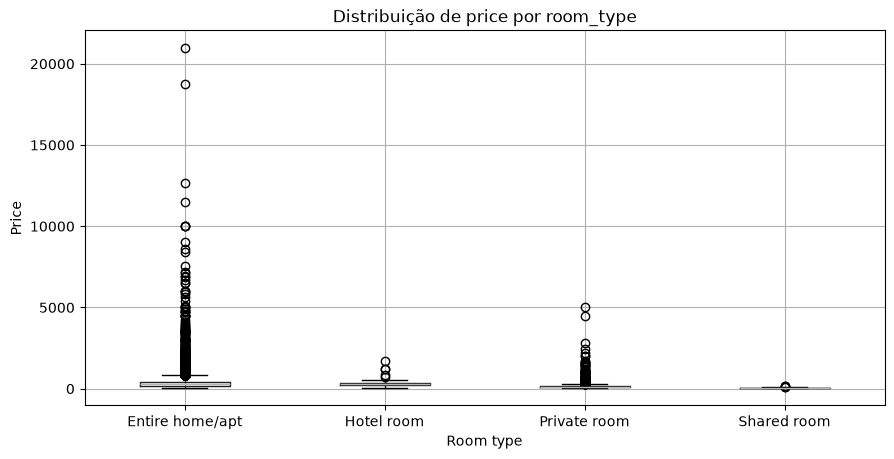

In [72]:
# ============================================================
# Associação entre room_type e price
# ============================================================

# Estatísticas de price por tipo de acomodação
price_room_type = (
    dados
    .groupby("room_type")["price"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .sort_values("median", ascending=False)
)

display(price_room_type)

# Boxplot para comparação visual
plt.figure(figsize=(10, 5))

dados.boxplot(
    column="price",
    by="room_type",
    figsize=(10, 5)
)

plt.title("Distribuição de price por room_type")
plt.suptitle("")
plt.xlabel("Room type")
plt.ylabel("Price")
plt.show()

In [73]:
# ============================================================
# Teste de Kruskal-Wallis: room_type x price
# ============================================================

# Como temos quatro grupos, distribuições bastante assimétricas, muitos outliers legítimos e tamanhos de grupos muito diferentes, eu evitaria ANOVA como primeira escolha. 
# Para nossa análise exploratória, Kruskal-Wallis é mais adequado.

# Separa os preços de cada categoria de room_type
grupos = [
    grupo["price"].values
    for nome, grupo in dados.groupby("room_type")
]

# Teste de Kruskal-Wallis
estatistica, p_valor = ss.kruskal(*grupos)

print(f"Estatística de Kruskal-Wallis: {estatistica:.4f}")
print(f"p-value: {p_valor:.6f}")

# Interpretação
if p_valor < 0.05:
    print("Existe diferença estatisticamente significativa entre os grupos.")
else:
    print("Não foi identificada diferença estatisticamente significativa entre os grupos.")

Estatística de Kruskal-Wallis: 4702.2595
p-value: 0.000000
Existe diferença estatisticamente significativa entre os grupos.


In [74]:
# ============================================================
# Tamanho do efeito: room_type x price
# ============================================================

# Número total de registros
n = len(dados)

# Número de grupos
k = dados["room_type"].nunique()

# Epsilon quadrado para o teste de Kruskal-Wallis
epsilon_quadrado = (estatistica - k + 1) / (n - k)

print(f"Epsilon quadrado: {epsilon_quadrado:.4f}")

Epsilon quadrado: 0.2079


In [75]:
# ============================================================
# Associação entre neighbourhood_group e price
# ============================================================

# Estatísticas de price por neighbourhood_group
price_regiao = (
    dados
    .groupby("neighbourhood_group")["price"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .sort_values("median", ascending=False)
)

print("Quantidade de regiões:", len(price_regiao))

print("\n10 regiões com maior mediana de price:")
display(price_regiao.head(10))

print("\n10 regiões com menor mediana de price:")
display(price_regiao.tail(10))


# ------------------------------------------------------------
# Teste de Kruskal-Wallis
# ------------------------------------------------------------

grupos_regiao = [
    grupo["price"].values
    for nome, grupo in dados.groupby("neighbourhood_group")
]

estatistica_regiao, p_valor_regiao = ss.kruskal(*grupos_regiao)

print(f"\nEstatística de Kruskal-Wallis: {estatistica_regiao:.4f}")
print(f"p-value: {p_valor_regiao:.6f}")


# ------------------------------------------------------------
# Tamanho do efeito - Epsilon quadrado
# ------------------------------------------------------------

n = len(dados)
k = dados["neighbourhood_group"].nunique()

epsilon_regiao = (
    (estatistica_regiao - k + 1) /
    (n - k)
)

print(f"Epsilon quadrado: {epsilon_regiao:.4f}")

Quantidade de regiões: 67

10 regiões com maior mediana de price:


,count,mean,median,std,min,max
neighbourhood_group,,,,,,
Queenstown-Lakes District,2565,588.446004,437.0,838.811912,45.0,21000.0
Mackenzie District,403,459.292804,391.0,278.240319,95.0,1857.0
Kaipara District,251,395.617530,331.0,369.604953,55.0,5000.0
Tauranga City,1040,374.575000,320.0,286.310549,40.0,4800.0
Thames-Coromandel District,882,391.339002,315.5,330.091814,20.0,6000.0
Taupo District,861,386.738676,307.0,358.590792,40.0,4500.0
Hurunui District,204,340.632353,296.5,206.345893,75.0,1766.0
Hastings District,398,388.972362,282.5,376.617187,45.0,3150.0
Chatham Islands Territory,6,276.666667,280.0,25.819889,250.0,300.0



10 regiões com menor mediana de price:


,count,mean,median,std,min,max
neighbourhood_group,,,,,,
Waimate District,17,191.176471,152.0,128.865354,90.0,632.0
Ōtorohanga District,29,196.586207,150.0,121.025239,85.0,639.0
Gore District,17,143.647059,140.0,42.823681,75.0,255.0
Waimakariri District,93,211.494624,140.0,211.423212,48.0,1027.0
Invercargill City,66,187.318182,140.0,139.264459,50.0,900.0
Upper Hutt City,61,160.557377,130.0,96.930993,54.0,479.0
Tararua District,23,160.782609,127.0,86.902221,73.0,379.0
Lower Hutt City,155,162.709677,125.0,114.657138,35.0,650.0
Palmerston North City,112,158.196429,120.0,102.262411,30.0,537.0



Estatística de Kruskal-Wallis: 4013.0699
p-value: 0.000000
Epsilon quadrado: 0.1751


In [76]:
# ============================================================
# Associação entre neighbourhood e price
# ============================================================

# Quantidade de registros por neighbourhood
frequencia_neighbourhood = dados["neighbourhood"].value_counts()

print("Quantidade de neighbourhoods:", len(frequencia_neighbourhood))

print(
    "Neighbourhoods com menos de 5 registros:",
    (frequencia_neighbourhood < 5).sum()
)

print(
    "Neighbourhoods com menos de 10 registros:",
    (frequencia_neighbourhood < 10).sum()
)


# ------------------------------------------------------------
# Teste de Kruskal-Wallis
# ------------------------------------------------------------

grupos_neighbourhood = [
    grupo["price"].values
    for nome, grupo in dados.groupby("neighbourhood")
]

estatistica_neighbourhood, p_valor_neighbourhood = ss.kruskal(
    *grupos_neighbourhood
)

print(
    f"\nEstatística de Kruskal-Wallis: "
    f"{estatistica_neighbourhood:.4f}"
)

print(f"p-value: {p_valor_neighbourhood:.6f}")


# ------------------------------------------------------------
# Tamanho do efeito
# ------------------------------------------------------------

n = len(dados)
k = dados["neighbourhood"].nunique()

epsilon_neighbourhood = (
    (estatistica_neighbourhood - k + 1) /
    (n - k)
)

print(f"Epsilon quadrado: {epsilon_neighbourhood:.4f}")

Quantidade de neighbourhoods: 209
Neighbourhoods com menos de 5 registros: 17
Neighbourhoods com menos de 10 registros: 36

Estatística de Kruskal-Wallis: 4969.8115
p-value: 0.000000
Epsilon quadrado: 0.2126


# 12. Seleção final para a modelagem

### Excluídos
`id`, `name`, `host_id`, `host_name` e `last_review`

`neighbourhood` também foi retirado da modelagem inicial por sua **alta cardinalidade (209 categorias)** e pela existência de outras representações geográficas.

### Variável alvo
`price`

### 9 preditores selecionados
- `neighbourhood_group`
- `latitude`, `longitude`
- `room_type`
- `minimum_nights`
- `number_of_reviews`
- `reviews_per_month`
- `calculated_host_listings_count`
- `availability_365`

> A base selecionada ficou completa, sem valores ausentes nos preditores.

In [77]:
# ============================================================
# Seleção inicial dos atributos para regressão
# ============================================================

atributos_modelo = [
    "price",
    "neighbourhood_group",
    "neighbourhood",
    "latitude",
    "longitude",
    "room_type",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365"
]

dados_modelo = dados[atributos_modelo].copy()

print("Dimensão da base original:")
print(dados.shape)

print("\nDimensão da base para modelagem:")
print(dados_modelo.shape)

print("\nAtributos selecionados:")
print(dados_modelo.columns.tolist())

print("\nValores ausentes:")
print(dados_modelo.isna().sum())

Dimensão da base original:
(22603, 16)

Dimensão da base para modelagem:
(22603, 11)

Atributos selecionados:
['price', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Valores ausentes:
price                             0
neighbourhood_group               0
neighbourhood                     0
latitude                          0
longitude                         0
room_type                         0
minimum_nights                    0
number_of_reviews                 0
reviews_per_month                 0
calculated_host_listings_count    0
availability_365                  0
dtype: int64


In [78]:
# ============================================================
# Preparação dos atributos para regressão
# ============================================================

# variável alvo
Y = dados["price"].copy()

# Atributos selecionados para a modelagem
atributos_modelo = [
    "neighbourhood_group",
    "latitude",
    "longitude",
    "room_type",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365"
]
X = dados[atributos_modelo].copy()

# ------------------------------------------------------------
# Validação
# ------------------------------------------------------------

print("Dimensão de X:", X.shape)
print("Dimensão de Y:", Y.shape)

print("\nValores ausentes em X")
print(X.isna().sum())

print("\nTipos de atributos:")
print(X.dtypes)



Dimensão de X: (22603, 9)
Dimensão de Y: (22603,)

Valores ausentes em X
neighbourhood_group               0
latitude                          0
longitude                         0
room_type                         0
minimum_nights                    0
number_of_reviews                 0
reviews_per_month                 0
calculated_host_listings_count    0
availability_365                  0
dtype: int64

Tipos de atributos:
neighbourhood_group                   str
latitude                          float64
longitude                         float64
room_type                             str
minimum_nights                    float64
number_of_reviews                   int64
reviews_per_month                 float64
calculated_host_listings_count    float64
availability_365                    int64
dtype: object


# 13. Preparação para regressão

Antes das transformações, os dados foram separados em:

- **80% treino:** 18.082 registros
- **20% teste:** 4.521 registros

Depois:
- categóricas → **One-Hot Encoding**
- numéricas → **StandardScaler**

O pré-processador foi ajustado **somente no conjunto de treino** e depois aplicado ao teste, evitando **data leakage**.

### Resultado
| Conjunto | Antes | Após pré-processamento |
|---|---:|---:|
| Treino | 18.082 × 9 | **18.082 × 78** |
| Teste | 4.521 × 9 | **4.521 × 78** |

**0 valores ausentes** nos dois conjuntos.

In [79]:
# ============================================================
# Divisão da base em treino e teste
# ============================================================

from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# Divisão dos dados
# 80% para treinamento e 20% para teste
# ------------------------------------------------------------

X_treino, X_teste, Y_treino, Y_teste = train_test_split(X, Y, test_size=0.20, random_state=42)

# ------------------------------------------------------------
# Validação
# ------------------------------------------------------------

print("Base completa:")
print("X:", X.shape)
print("Y:", Y.shape)

print("\nTreinamento:")
print("X_treino:", X_treino.shape)
print("Y_teste:", Y_teste.shape)

print("\nTeste:")
print("X_teste:", X_teste.shape)
print("Y_teste:", Y_teste.shape)

print("\nPercentual de treinamento:", f"{len(X_treino) / len(X) * 100:.2f}%")
print("Percentual de teste:", f"{len(X_teste) / len(X) * 100:.2f}%")


Base completa:
X: (22603, 9)
Y: (22603,)

Treinamento:
X_treino: (18082, 9)
Y_teste: (4521,)

Teste:
X_teste: (4521, 9)
Y_teste: (4521,)

Percentual de treinamento: 80.00%
Percentual de teste: 20.00%


In [80]:
# ============================================================
# Codificação e normalização dos atributos
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ------------------------------------------------------------
# Define os atributos categóricos e numéricos
# ------------------------------------------------------------

atributos_categoricos = ["neighbourhood_group", "room_type"]
atributos_numericos = [
    "latitude",
    "longitude",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365"
]

# ------------------------------------------------------------
# Define as transformações
# ------------------------------------------------------------

pre_processador = ColumnTransformer(transformers=[("categoricos", OneHotEncoder(handle_unknown="ignore", sparse_output=False), atributos_categoricos),
                                                  ("numericos", StandardScaler(), atributos_numericos)])

# ------------------------------------------------------------
# Aprende as transformações somente com os dados de treino
# ------------------------------------------------------------

X_treino_processado = pre_processador.fit_transform(X_treino)

# ------------------------------------------------------------
# Aplica as mesmas transformações aos dados de teste
# ------------------------------------------------------------

X_teste_processado = pre_processador.transform(X_teste)

# ------------------------------------------------------------
# Validação
# ------------------------------------------------------------

print("Antes do pré-processamento:")
print("X_treino:", X_treino.shape)
print("Y_treino:", Y_treino.shape)

print("\nApós o pré-processamento:")
print("X_treino_processado:", X_treino_processado.shape)
print("X_teste_processado:", X_teste_processado.shape)

print("\nValores ausentes:")
print(
    "Treino:",
    pd.DataFrame(X_treino_processado).isna().sum().sum()
)
print(
    "Teste:",
    pd.DataFrame(X_teste_processado).isna().sum().sum()
)

Antes do pré-processamento:
X_treino: (18082, 9)
Y_treino: (18082,)

Após o pré-processamento:
X_treino_processado: (18082, 78)
X_teste_processado: (4521, 78)

Valores ausentes:
Treino: 0
Teste: 0


# Conclusão

O trabalho mostrou que pré-processamento não é apenas aplicar funções de limpeza.

Os principais aprendizados foram:

- investigar a causa antes de converter ou remover;
- diferenciar valor ausente de ausência com significado;
- diferenciar **outlier estatístico** de **anomalia real**;
- combinar critérios estatísticos com entendimento do domínio;
- evitar data leakage na preparação para modelagem.

### Resultado final
A base foi descrita, tratada, validada e preparada para a próxima etapa:

> **aplicação de modelos de regressão para inferir `price`.**